# CSA17 Artificial Intelligence - Assignment 3 (CO3)
Athisaya U - 192571001

Each module is written to disk with `%%writefile` and then imported. Run all cells from top to bottom. Raw data goes to `data/`, figures to `figures/`.

In [1]:
import csv, os, math, time, random
os.makedirs('data', exist_ok=True); os.makedirs('figures', exist_ok=True)
def save_csv(name, rows):
    with open(os.path.join('data', name), 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
import platform; print('Python', platform.python_version(), '|', platform.machine())

Python 3.13.18 | x86_64


## Shared propositional core

In [2]:
%%writefile u3_logic.py
# Shared propositional logic core: formulas, evaluation, compiled model checking, CNF
import itertools, time

# formula = 'Sym' | ('not', f) | ('and', f, ...) | ('or', f, ...) | ('imp', a, b) | ('iff', a, b)
def Not(f): return ('not', f)
def And(*fs): return fs[0] if len(fs) == 1 else ('and',) + tuple(fs)
def Or(*fs): return fs[0] if len(fs) == 1 else ('or',) + tuple(fs)
def Imp(a, b): return ('imp', a, b)
def Iff(a, b): return ('iff', a, b)

def symbols(f, out=None):
    out = set() if out is None else out
    if isinstance(f, str):
        out.add(f)
    else:
        for g in f[1:]:
            symbols(g, out)
    return out

def show(f):
    if isinstance(f, str): return f
    op = f[0]
    if op == 'not': return '¬' + show(f[1])
    sep = {'and': ' ∧ ', 'or': ' ∨ ', 'imp': ' ⇒ ', 'iff': ' ⇔ '}[op]
    return '(' + sep.join(show(g) for g in f[1:]) + ')'

def pycode(f, idx):
    if isinstance(f, str): return f'v[{idx[f]}]'
    op = f[0]
    if op == 'not': return f'(not {pycode(f[1], idx)})'
    if op == 'and': return '(' + ' and '.join(pycode(g, idx) for g in f[1:]) + ')'
    if op == 'or': return '(' + ' or '.join(pycode(g, idx) for g in f[1:]) + ')'
    if op == 'imp': return f'((not {pycode(f[1], idx)}) or {pycode(f[2], idx)})'
    if op == 'iff': return f'({pycode(f[1], idx)} == {pycode(f[2], idx)})'

def tt_entails(kb, alpha, limit_symbols=26):
    """Truth-table model checking: enumerate every model of the symbols in KB and
    alpha. Returns 'entailed', 'negation entailed' or 'neither' plus counters."""
    syms = sorted(set().union(*(symbols(s) for s in kb)) | symbols(alpha))
    m = len(syms)
    st = dict(symbols=m, sentences=len(kb), models=0, kb_evals=0, kb_true=0, seconds=0.0)
    if m > limit_symbols:
        st['models'] = 2 ** m; st['infeasible'] = True
        return None, st
    idx = {s: i for i, s in enumerate(syms)}
    kbf = eval('lambda v: ' + (' and '.join(pycode(s, idx) for s in kb) or 'True'))
    af = eval('lambda v: ' + pycode(alpha, idx))
    t0 = time.perf_counter()
    pos = neg = True
    for v in itertools.product((False, True), repeat=m):
        st['models'] += 1; st['kb_evals'] += 1
        if kbf(v):
            st['kb_true'] += 1
            a = af(v)
            pos = pos and a
            neg = neg and not a
    st['seconds'] = time.perf_counter() - t0
    if st['kb_true'] == 0:
        return 'KB unsatisfiable', st
    return ('entailed' if pos else 'negation entailed' if neg else 'neither'), st

# ---------- CNF conversion ----------
def elim(f):
    """Remove ⇔ and ⇒."""
    if isinstance(f, str): return f
    op = f[0]
    if op == 'iff':
        a, b = elim(f[1]), elim(f[2])
        return ('and', ('or', ('not', a), b), ('or', ('not', b), a))
    if op == 'imp':
        return ('or', ('not', elim(f[1])), elim(f[2]))
    return (op,) + tuple(elim(g) for g in f[1:])

def push_not(f):
    """Move ¬ inwards (De Morgan, double negation)."""
    if isinstance(f, str): return f
    op = f[0]
    if op == 'not':
        g = f[1]
        if isinstance(g, str): return f
        if g[0] == 'not': return push_not(g[1])
        if g[0] == 'and': return ('or',) + tuple(push_not(('not', h)) for h in g[1:])
        if g[0] == 'or': return ('and',) + tuple(push_not(('not', h)) for h in g[1:])
    return (op,) + tuple(push_not(g) for g in f[1:])

def to_clauses(f):
    """Distribute ∨ over ∧; return a list of clauses (frozensets of literals 'P' / '~P')."""
    if isinstance(f, str): return [frozenset([f])]
    op = f[0]
    if op == 'not': return [frozenset(['~' + f[1]])]
    if op == 'and':
        out = []
        for g in f[1:]: out += to_clauses(g)
        return out
    if op == 'or':
        acc = [frozenset()]
        for g in f[1:]:
            acc = [a | c for a in acc for c in to_clauses(g)]
        return acc

def cnf(f):
    return [c for c in to_clauses(push_not(elim(f))) if not is_tautology(c)]

def neg(l): return l[1:] if l.startswith('~') else '~' + l
def is_tautology(c): return any(neg(l) in c for l in c)
def show_clause(c): return '{' + ', '.join(sorted(l.replace('~', '¬') for l in c)) + '}' if c else '{} (empty)'

Writing u3_logic.py


In [3]:
from u3_logic import *

## Task 1 - Wumpus world: model checking and inference rules

In [4]:
%%writefile u3_t1_wumpus.py
# Task 1 - Wumpus-world KB, model checking and inference-rule derivation
import itertools
from u3_logic import *

def nb(x, y, n):
    return [(a, b) for a, b in ((x - 1, y), (x + 1, y), (x, y - 1), (x, y + 1)) if 1 <= a <= n and 1 <= b <= n]

def wumpus_kb(n):
    """General rules of an n x n Wumpus world (no percepts yet)."""
    kb = [Not('P11'), Not('W11')]                                 # start square is safe
    for x in range(1, n + 1):
        for y in range(1, n + 1):
            kb.append(Iff(f'B{x}{y}', Or(*[f'P{a}{b}' for a, b in nb(x, y, n)])))
            kb.append(Iff(f'S{x}{y}', Or(*[f'W{a}{b}' for a, b in nb(x, y, n)])))
    squares = [(x, y) for x in range(1, n + 1) for y in range(1, n + 1)]
    kb.append(Or(*[f'W{x}{y}' for x, y in squares]))              # at least one wumpus
    for (a, b), (c, d) in itertools.combinations(squares, 2):     # at most one wumpus
        kb.append(Or(Not(f'W{a}{b}'), Not(f'W{c}{d}')))
    return kb

def counts(n):
    q = n * n
    return dict(n=n, symbols=4 * q, sentences=2 + 2 * q + 1 + q * (q - 1) // 2, models=2 ** (4 * q))

def percepts(n):
    """Designed percept sequences (consistent with a hidden world)."""
    if n == 2:   # visited [1,1] only: no breeze, stench (pit at [2,2], wumpus at [1,2])
        return [Not('B11'), 'S11']
    # visited [1,1], [2,1], [1,2] (pit at [3,1], wumpus at [1,3])
    return [Not('B11'), Not('S11'), 'B21', Not('S21'), Not('B12'), 'S12']

QUERIES = {
    2: [('[2,1] has no pit', Not('P21')), ('[1,2] has a pit', 'P12'), ('wumpus in [2,1]', 'W21')],
    3: [('[2,2] is safe', And(Not('P22'), Not('W22'))), ('[3,1] is pit-free', Not('P31')), ('[3,2] is pit-free', Not('P32'))],
}
QUERIES[4] = QUERIES[3]

def relevant(kb, alpha):
    """Keep only the sentences connected to the query through shared symbols,
    starting from the query and never crossing the global wumpus-count sentences
    or the rules of squares whose percept is still unknown."""
    known = {s for s in kb if isinstance(s, str) or (s[0] == 'not' and isinstance(s[1], str))}
    known_syms = set().union(*(symbols(s) for s in known))
    usable = [s for s in kb if s in known or
              (s[0] == 'iff' and s[1] in known_syms)]            # rule of a visited square
    need, chosen, changed = set(symbols(alpha)), [], True
    while changed:
        changed = False
        for s in usable:
            if s not in chosen and symbols(s) & need:
                chosen.append(s); need |= symbols(s); changed = True
    return chosen

def run_model_checking(n, restrict):
    kb = wumpus_kb(n) + percepts(n)
    rows = []
    for name, q in QUERIES[n]:
        k = relevant(kb, q) if restrict else kb
        res, st = tt_entails(k, q)
        rows.append(dict(n=n, restricted=restrict, query=name, answer=res if res else 'infeasible',
                         symbols=st['symbols'], sentences=st['sentences'], models=st['models'],
                         kb_evals=st['kb_evals'] if res else 0, seconds=round(st['seconds'], 4)))
    return rows

# ---------- Part B: inference rules ----------
def derive(kb, goals, max_steps=500):
    """Forward application of sound rules until every goal is derived.
    Rules: Biconditional elimination, Contraposition (as an equivalence),
    Modus Ponens, De Morgan, And-Elimination, Unit Resolution."""
    known, why = [], {}
    def add(f, rule, parents):
        if f not in why:
            known.append(f); why[f] = (rule, parents); return True
        return False
    for s in kb: add(s, 'KB', ())
    steps, i, progress = 0, 0, False
    while any(g not in why for g in goals) and steps < max_steps:
        if i == len(known):                  # end of a pass: start again if anything new appeared
            if not progress: break
            i, progress = 0, False
        f = known[i]; i += 1
        new = []
        if not isinstance(f, str):
            op = f[0]
            if op == 'iff':
                new += [(Imp(f[1], f[2]), 'Biconditional elimination', (f,)), (Imp(f[2], f[1]), 'Biconditional elimination', (f,))]
            if op == 'imp':
                new.append((Imp(Not(f[2]) if not (isinstance(f[2], tuple) and f[2][0] == 'not') else f[2][1],
                                Not(f[1]) if not (isinstance(f[1], tuple) and f[1][0] == 'not') else f[1][1]), 'Contraposition', (f,)))
                if f[1] in why: new.append((f[2], 'Modus Ponens', (f, f[1])))
            if op == 'not' and not isinstance(f[1], str) and f[1][0] == 'or':
                new.append((And(*[Not(g) for g in f[1][1:]]), 'De Morgan', (f,)))
            if op == 'and':
                new += [(g, 'And-Elimination', (f,)) for g in f[1:]]
            if op == 'or':
                for g in f[1:]:
                    comp = g[1] if isinstance(g, tuple) and g[0] == 'not' else Not(g)
                    if comp in why:
                        rest = [h for h in f[1:] if h != g]
                        new.append((Or(*rest), 'Unit Resolution', (f, comp)))
        # Modus Ponens where f is the premise of an implication already known
        for h in list(why):
            if isinstance(h, tuple) and h[0] == 'imp' and h[1] == f:
                new.append((h[2], 'Modus Ponens', (h, f)))
        for g, rule, parents in new:
            if add(g, rule, parents):
                steps += 1; progress = True
    def proof(g, seen=None):
        seen = set() if seen is None else seen
        if g in seen: return []
        seen.add(g); rule, ps = why[g]
        out = []
        for p in ps: out += proof(p, seen)
        return out + ([(g, rule, ps)] if rule != 'KB' else [])
    return steps, {g: proof(g) for g in goals if g in why}

def soundness_table(premises, conclusion):
    """Truth table over the symbols; the rule is sound iff the conclusion is true
    in every row where all premises are true."""
    syms = sorted(set().union(*(symbols(p) for p in premises)) | symbols(conclusion))
    idx = {s: i for i, s in enumerate(syms)}
    fp = [eval('lambda v: ' + pycode(p, idx)) for p in premises]
    fc = eval('lambda v: ' + pycode(conclusion, idx))
    rows, sound = [], True
    for v in itertools.product((False, True), repeat=len(syms)):
        ps = [f(v) for f in fp]; c = fc(v)
        rows.append((v, ps, c))
        if all(ps) and not c: sound = False
    return syms, rows, sound

RULES = {
    'Modus Ponens': (['P', Imp('P', 'Q')], 'Q'),
    'And-Elimination': ([And('P', 'Q')], 'P'),
    'Unit Resolution': ([Or('L', 'M'), Not('M')], 'L'),
    'Biconditional elimination': ([Iff('P', 'Q')], Imp('P', 'Q')),
    'Contraposition': ([Imp('P', 'Q')], Imp(Not('Q'), Not('P'))),
    'De Morgan': ([Not(Or('P', 'Q'))], And(Not('P'), Not('Q'))),
}

def compare_methods(n, goal):
    kb = wumpus_kb(n) + percepts(n)
    full = tt_entails(kb, goal)[1]
    res, rst = tt_entails(relevant(kb, goal), goal)
    steps, pr = derive(kb, [goal])
    return dict(n=n, query=show(goal), full_models=full['models'], restricted_models=rst['models'],
                rule_applications=steps, proof_length=len(pr[goal]))

Writing u3_t1_wumpus.py


In [5]:
from u3_t1_wumpus import *

In [6]:
for n in (2, 3, 4):
    c = counts(n); kb = wumpus_kb(n)
    print(f"n={n}: symbols 4n^2 = {c['symbols']:3} | sentences = {c['sentences']:4} (built: {len(kb)}) | models 2^m = {c['models']:.3e}")
kb3 = wumpus_kb(3) + percepts(3)
for name, q in QUERIES[3]:
    rel = relevant(kb3, q)
    print(f"query '{name}': relevant sentences {len(rel)}, relevant symbols {sorted(set().union(symbols(q), *(symbols(s) for s in rel)))}")

n=2: symbols 4n^2 =  16 | sentences =   17 (built: 17) | models 2^m = 6.554e+04
n=3: symbols 4n^2 =  36 | sentences =   57 (built: 57) | models 2^m = 6.872e+10
n=4: symbols 4n^2 =  64 | sentences =  155 (built: 155) | models 2^m = 1.845e+19
query '[2,2] is safe': relevant sentences 10, relevant symbols ['B12', 'B21', 'P11', 'P13', 'P22', 'P31', 'S12', 'S21', 'W11', 'W13', 'W22', 'W31']
query '[3,1] is pit-free': relevant sentences 5, relevant symbols ['B12', 'B21', 'P11', 'P13', 'P22', 'P31']
query '[3,2] is pit-free': relevant sentences 0, relevant symbols ['P32']


In [7]:
rows = []
for n in (2, 3, 4):
    for restrict in (False, True):
        rows += run_model_checking(n, restrict)
per_model = rows[0]['seconds'] / rows[0]['models']           # measured cost per model (n = 2, full KB)
for r in rows:
    sec = r['models'] * per_model
    est = '' if r['answer'] != 'infeasible' else (f"  (estimated {sec / 3600:.1f} hours)" if sec < 86400 * 365 else f"  (estimated {sec / 86400 / 365:.1e} years)")
    print(f"n={r['n']} {'relevant' if r['restricted'] else 'full KB '} | {r['query']:18} | {r['answer']:17} | "
          f"symbols {r['symbols']:2} | models {r['models']:.3e} | KB evals {r['kb_evals']:6} | {r['seconds']:.4f} s{est}")
save_csv('task1_model_checking.csv', rows)

n=2 full KB  | [2,1] has no pit   | entailed          | symbols 16 | models 6.554e+04 | KB evals  65536 | 0.0112 s
n=2 full KB  | [1,2] has a pit    | negation entailed | symbols 16 | models 6.554e+04 | KB evals  65536 | 0.0118 s
n=2 full KB  | wumpus in [2,1]    | neither           | symbols 16 | models 6.554e+04 | KB evals  65536 | 0.0116 s
n=2 relevant | [2,1] has no pit   | entailed          | symbols  3 | models 8.000e+00 | KB evals      8 | 0.0000 s
n=2 relevant | [1,2] has a pit    | negation entailed | symbols  3 | models 8.000e+00 | KB evals      8 | 0.0000 s
n=2 relevant | wumpus in [2,1]    | neither           | symbols  3 | models 8.000e+00 | KB evals      8 | 0.0000 s
n=3 full KB  | [2,2] is safe      | infeasible        | symbols 36 | models 6.872e+10 | KB evals      0 | 0.0000 s  (estimated 3.3 hours)
n=3 full KB  | [3,1] is pit-free  | infeasible        | symbols 36 | models 6.872e+10 | KB evals      0 | 0.0000 s  (estimated 3.3 hours)
n=3 full KB  | [3,2] is pit-free  

In [8]:
kb3 = wumpus_kb(3) + percepts(3)
goals = [Not('P21'), Not('W21'), Not('P22'), Not('W22'), 'P31', 'W13']
steps, proofs = derive(kb3, goals)
print('rule applications to derive all six sentences:', steps)
for g in (Not('P22'), 'P31'):
    print(f"proof of {show(g)} ({len(proofs[g])} steps):")
    for f, rule, _ in proofs[g]:
        print(f"   {rule:26} {show(f)}")
rows = [compare_methods(n, g) for n in (3, 4) for g in (Not('P22'), Not('W22'), 'P31')]
for r in rows:
    print(f"n={r['n']} {r['query']:5}: model checking full {r['full_models']:.2e} models, relevant {r['restricted_models']:3} | "
          f"rule applications {r['rule_applications']:3} | proof length {r['proof_length']}")
save_csv('task1_rules_vs_mc.csv', rows)

rule applications to derive all six sentences: 105
proof of ¬P22 (5 steps):
   Biconditional elimination  ((P22 ∨ P11 ∨ P13) ⇒ B12)
   Contraposition             (¬B12 ⇒ ¬(P22 ∨ P11 ∨ P13))
   Modus Ponens               ¬(P22 ∨ P11 ∨ P13)
   De Morgan                  (¬P22 ∧ ¬P11 ∧ ¬P13)
   And-Elimination            ¬P22
proof of P31 (9 steps):
   Biconditional elimination  (B21 ⇒ (P11 ∨ P31 ∨ P22))
   Modus Ponens               (P11 ∨ P31 ∨ P22)
   Unit Resolution            (P31 ∨ P22)
   Biconditional elimination  ((P22 ∨ P11 ∨ P13) ⇒ B12)
   Contraposition             (¬B12 ⇒ ¬(P22 ∨ P11 ∨ P13))
   Modus Ponens               ¬(P22 ∨ P11 ∨ P13)
   De Morgan                  (¬P22 ∧ ¬P11 ∧ ¬P13)
   And-Elimination            ¬P22
   Unit Resolution            P31
n=3 ¬P22 : model checking full 6.87e+10 models, relevant  64 | rule applications  91 | proof length 5
n=3 ¬W22 : model checking full 6.87e+10 models, relevant  64 | rule applications  93 | proof length 5
n=3 P31  : model c

In [9]:
for name, (prem, concl) in RULES.items():
    syms, rows, sound = soundness_table(prem, concl)
    good = [r for r in rows if all(r[1])]
    print(f"{name:26} premises {', '.join(show(p) for p in prem):22} conclusion {show(concl):12} "
          f"rows {len(rows)} | rows with all premises true {len(good)} | conclusion true in all of them: {sound}")

Modus Ponens               premises P, (P ⇒ Q)             conclusion Q            rows 4 | rows with all premises true 1 | conclusion true in all of them: True
And-Elimination            premises (P ∧ Q)                conclusion P            rows 4 | rows with all premises true 1 | conclusion true in all of them: True
Unit Resolution            premises (L ∨ M), ¬M            conclusion L            rows 4 | rows with all premises true 1 | conclusion true in all of them: True
Biconditional elimination  premises (P ⇔ Q)                conclusion (P ⇒ Q)      rows 4 | rows with all premises true 2 | conclusion true in all of them: True
Contraposition             premises (P ⇒ Q)                conclusion (¬Q ⇒ ¬P)    rows 4 | rows with all premises true 3 | conclusion true in all of them: True
De Morgan                  premises ¬(P ∨ Q)               conclusion (¬P ∧ ¬Q)    rows 4 | rows with all premises true 1 | conclusion true in all of them: True


## Task 2 - Model checking versus resolution

In [10]:
%%writefile u3_t2_resolution.py
# Task 2 - Propositional resolution refutation vs truth-table model checking
import time, itertools
from collections import deque
from u3_logic import *

def resolve(c1, c2, st):
    out = []
    for l in c1:
        if neg(l) in c2:
            st['attempted'] += 1
            r = (c1 - {l}) | (c2 - {neg(l)})
            if is_tautology(r):
                st['tautologies'] += 1
                continue
            out.append(frozenset(r))
    return out

def pl_resolution(kb, alpha, cap=200_000, order='fifo'):
    """Refutation: KB ∧ ¬α is turned into clauses; resolve pairs until the empty
    clause appears (entailed) or nothing new can be produced (not entailed).
    Given-clause loop with forward and backward subsumption."""
    st = dict(input_clauses=0, generated=0, attempted=0, tautologies=0, subsumed=0, kept=0, seconds=0.0)
    t0 = time.perf_counter()
    start = []
    for s in kb + [Not(alpha)]:
        for c in to_clauses(push_not(elim(s))):
            if is_tautology(c): st['tautologies'] += 1
            elif c not in start: start.append(c)
    st['input_clauses'] = len(start)
    todo = deque(sorted(start, key=len) if order == 'short' else start)
    seen, processed, parent = set(start), [], {c: None for c in start}
    while todo:
        if st['generated'] > cap:
            st['kept'] = len(processed) + len(todo)
            st['seconds'] = time.perf_counter() - t0
            return None, st, parent
        g = todo.popleft()
        if any(p <= g for p in processed):              # forward subsumption
            st['subsumed'] += 1; continue
        before = len(processed)
        processed = [p for p in processed if not g <= p]  # backward subsumption
        st['subsumed'] += before - len(processed)
        for p in processed:
            for r in resolve(g, p, st):
                st['generated'] += 1
                if r not in parent: parent[r] = (g, p)
                if not r:
                    st['kept'] = len(processed) + len(todo)
                    st['seconds'] = time.perf_counter() - t0
                    return True, st, parent
                if r not in seen:
                    seen.add(r); todo.append(r)
        processed.append(g)
    st['kept'] = len(processed)
    st['seconds'] = time.perf_counter() - t0
    return False, st, parent

def proof_tree(parent, c=frozenset(), depth=0, out=None):
    out = [] if out is None else out
    out.append('    ' * depth + show_clause(c))
    if parent.get(c):
        for p in parent[c]:
            proof_tree(parent, p, depth + 1, out)
    return out

# ---------- Smart-building access-control policy ----------
POLICY = [
    Iff('BadgeValid', And('BadgeActive', Not('BadgeExpired'))),           # R1  biconditional
    Or('Employee', 'Visitor'),                                            # R2  disjunction
    Imp('Visitor', Not('Employee')),                                      # R3
    Iff('WorkHours', Not('Night')),                                       # R4  biconditional
    Iff('Emergency', Or('FireAlarm', 'ManualOverride')),                  # R5  biconditional + disjunction
    Imp(And('Employee', 'BadgeValid', 'WorkHours'), 'LabAccess'),         # R6
    Imp(And('Visitor', 'Escorted', 'BadgeValid', 'WorkHours'), 'LobbyAccess'),  # R7
    Imp('LabAccess', 'LobbyAccess'),                                      # R8
    Imp(And('Admin', 'BadgeValid'), 'ServerRoom'),                        # R9
    Imp('ServerRoom', 'LabAccess'),                                       # R10
    Imp('Emergency', And('ExitsUnlocked', Not('ServerRoom'))),            # R11 emergency override
    Imp(And('Night', Not('Admin')), Not('LabAccess')),                    # R12
    Imp('Admin', 'Employee'),                                             # R13
]
SCENARIO = ['BadgeActive', Not('BadgeExpired'), 'Admin', Not('FireAlarm'), Not('ManualOverride')]

def chain(k):
    """Implication chain A0, A0⇒A1, ..., A(k-1)⇒Ak; query Ak."""
    return ['A0'] + [Imp(f'A{i}', f'A{i + 1}') for i in range(k)], f'A{k}'

def pigeonhole(n):
    """n+1 pigeons in n holes: unsatisfiable, so it entails any query."""
    kb = [Or(*[f'p{i}h{j}' for j in range(n)]) for i in range(n + 1)]
    for j in range(n):
        for a, b in itertools.combinations(range(n + 1), 2):
            kb.append(Or(Not(f'p{a}h{j}'), Not(f'p{b}h{j}')))
    return kb, 'Q'

def wide_or(k):
    """Few symbols, wide disjunctions: model checking enumerates 2^k models quickly,
    resolution must combine long clauses."""
    syms = [f'X{i}' for i in range(k)]
    kb = [Or(*syms)] + [Imp(s, 'Goal') for s in syms]
    return kb, 'Goal'

Writing u3_t2_resolution.py


In [11]:
from u3_t2_resolution import *

In [12]:
kb = POLICY + SCENARIO
for i, r in enumerate(POLICY, 1): print(f"R{i:<2} {show(r)}")
print('facts:', ', '.join(show(f) for f in SCENARIO))
for i in (0, 4, 5):
    print(f"CNF(R{i + 1}):", '  '.join(show_clause(c) for c in cnf(POLICY[i])))
rows = []
for q in ('ServerRoom', 'LobbyAccess', 'ExitsUnlocked'):
    res, st, par = pl_resolution(kb, q)
    ans, mst = tt_entails(kb, q)
    rows.append(dict(query=q, resolution=res, model_checking=ans, **{k: st[k] for k in ('input_clauses', 'generated', 'attempted', 'tautologies', 'subsumed')}, models=mst['models']))
    print(f"{q:13} resolution {str(res):5} (clauses {st['input_clauses']}, generated {st['generated']}, attempted {st['attempted']}, "
          f"tautologies {st['tautologies']}, subsumed {st['subsumed']}) | model checking: {ans}, {mst['models']} models")
save_csv('task2_policy.csv', rows)
res, st, par = pl_resolution(kb, 'LobbyAccess')
print('Proof tree (empty clause at the root):'); print('\n'.join(proof_tree(par)))

R1  (BadgeValid ⇔ (BadgeActive ∧ ¬BadgeExpired))
R2  (Employee ∨ Visitor)
R3  (Visitor ⇒ ¬Employee)
R4  (WorkHours ⇔ ¬Night)
R5  (Emergency ⇔ (FireAlarm ∨ ManualOverride))
R6  ((Employee ∧ BadgeValid ∧ WorkHours) ⇒ LabAccess)
R7  ((Visitor ∧ Escorted ∧ BadgeValid ∧ WorkHours) ⇒ LobbyAccess)
R8  (LabAccess ⇒ LobbyAccess)
R9  ((Admin ∧ BadgeValid) ⇒ ServerRoom)
R10 (ServerRoom ⇒ LabAccess)
R11 (Emergency ⇒ (ExitsUnlocked ∧ ¬ServerRoom))
R12 ((Night ∧ ¬Admin) ⇒ ¬LabAccess)
R13 (Admin ⇒ Employee)
facts: BadgeActive, ¬BadgeExpired, Admin, ¬FireAlarm, ¬ManualOverride
CNF(R1): {BadgeActive, ¬BadgeValid}  {¬BadgeExpired, ¬BadgeValid}  {BadgeExpired, BadgeValid, ¬BadgeActive}
CNF(R5): {FireAlarm, ManualOverride, ¬Emergency}  {Emergency, ¬FireAlarm}  {Emergency, ¬ManualOverride}
CNF(R6): {LabAccess, ¬BadgeValid, ¬Employee, ¬WorkHours}
ServerRoom    resolution True  (clauses 25, generated 303, attempted 338, tautologies 35, subsumed 82) | model checking: entailed, 65536 models
LobbyAccess   resol

ExitsUnlocked resolution False (clauses 25, generated 399, attempted 434, tautologies 35, subsumed 211) | model checking: neither, 65536 models


Proof tree (empty clause at the root):
{} (empty)
    {¬BadgeValid}
        {¬ServerRoom}
            {LobbyAccess, ¬ServerRoom}
                {LabAccess, ¬ServerRoom}
                {LobbyAccess, ¬LabAccess}
            {¬LobbyAccess}
        {ServerRoom, ¬BadgeValid}
            {Admin}
            {ServerRoom, ¬Admin, ¬BadgeValid}
    {BadgeValid}
        {BadgeExpired, BadgeValid}
            {BadgeActive}
            {BadgeExpired, BadgeValid, ¬BadgeActive}
        {¬BadgeExpired}


In [13]:
rows = []
for k in (10, 20, 40, 80):
    kb, q = chain(k)
    for query, label in ((q, 'entailed'), ('B', 'not entailed')):
        res, st, _ = pl_resolution(kb, query)
        ans, mst = tt_entails(kb, query)
        rows.append(dict(chain=k, query=label, result=res, **{x: st[x] for x in ('input_clauses', 'generated', 'attempted', 'tautologies', 'subsumed')},
                         res_seconds=round(st['seconds'], 4), mc_models=mst['models'], mc_seconds=round(mst['seconds'], 3) if ans else 'infeasible'))
        print(f"chain {k:2} {label:12}: resolution {str(res):5} gen {st['generated']:6} att {st['attempted']:6} taut {st['tautologies']} "
              f"subs {st['subsumed']:5} {st['seconds']:.4f} s | model checking {mst['models']:.2e} models, "
              + (f"{mst['seconds']:.3f} s" if ans else 'infeasible'))
save_csv('task2_chains.csv', rows)

chain 10 entailed    : resolution True  gen    159 att    159 taut 0 subs    34 0.0011 s | model checking 2.05e+03 models, 0.001 s
chain 10 not entailed: resolution False gen    172 att    172 taut 0 subs    55 0.0013 s | model checking 4.10e+03 models, 0.001 s


chain 20 entailed    : resolution True  gen    914 att    914 taut 0 subs   119 0.0053 s | model checking 2.10e+06 models, 0.393 s


chain 20 not entailed: resolution False gen   1129 att   1129 taut 0 subs   210 0.0075 s | model checking 4.19e+06 models, 0.963 s
chain 40 entailed    : resolution True  gen   6180 att   6180 taut 0 subs   445 0.0544 s | model checking 2.20e+12 models, infeasible
chain 40 not entailed: resolution False gen   8095 att   8095 taut 0 subs   820 0.0868 s | model checking 4.40e+12 models, infeasible


chain 80 entailed    : resolution True  gen  45368 att  45368 taut 0 subs  1721 0.7632 s | model checking 2.42e+24 models, infeasible


chain 80 not entailed: resolution False gen  61115 att  61115 taut 0 subs  3240 1.2527 s | model checking 4.84e+24 models, infeasible


In [14]:
rows = []
for name, maker, sizes, cap in (('pigeonhole', pigeonhole, (2, 3, 4), 100_000), ('wide-or', wide_or, (4, 8, 12, 14), 60_000)):
    for n in sizes:
        kb, q = maker(n)
        ans, mst = tt_entails(kb, q)
        res, st, _ = pl_resolution(kb, q, cap=cap)
        rows.append(dict(family=name, size=n, symbols=mst['symbols'], mc_answer=ans, mc_models=mst['models'], mc_seconds=round(mst['seconds'], 4),
                         res_result=res, res_generated=st['generated'], res_seconds=round(st['seconds'], 3)))
        print(f"{name:10} n={n:2} symbols {mst['symbols']:2}: model checking {mst['models']:8} models {mst['seconds']:.4f} s | "
              f"resolution {'CAP' if res is None else res} generated {st['generated']:6} {st['seconds']:.3f} s")
save_csv('task2_families.csv', rows)

pigeonhole n= 2 symbols  7: model checking      128 models 0.0000 s | resolution True generated    417 0.001 s


pigeonhole n= 3 symbols 13: model checking     8192 models 0.0024 s | resolution CAP generated 100116 0.463 s


pigeonhole n= 4 symbols 21: model checking  2097152 models 0.9060 s | resolution CAP generated 100078 0.747 s
wide-or    n= 4 symbols  5: model checking       32 models 0.0000 s | resolution True generated     91 0.000 s
wide-or    n= 8 symbols  9: model checking      512 models 0.0003 s | resolution True generated   2359 0.032 s


wide-or    n=12 symbols 13: model checking     8192 models 0.0036 s | resolution True generated  53379 5.618 s


wide-or    n=14 symbols 15: model checking    32768 models 0.0150 s | resolution CAP generated  60003 9.229 s


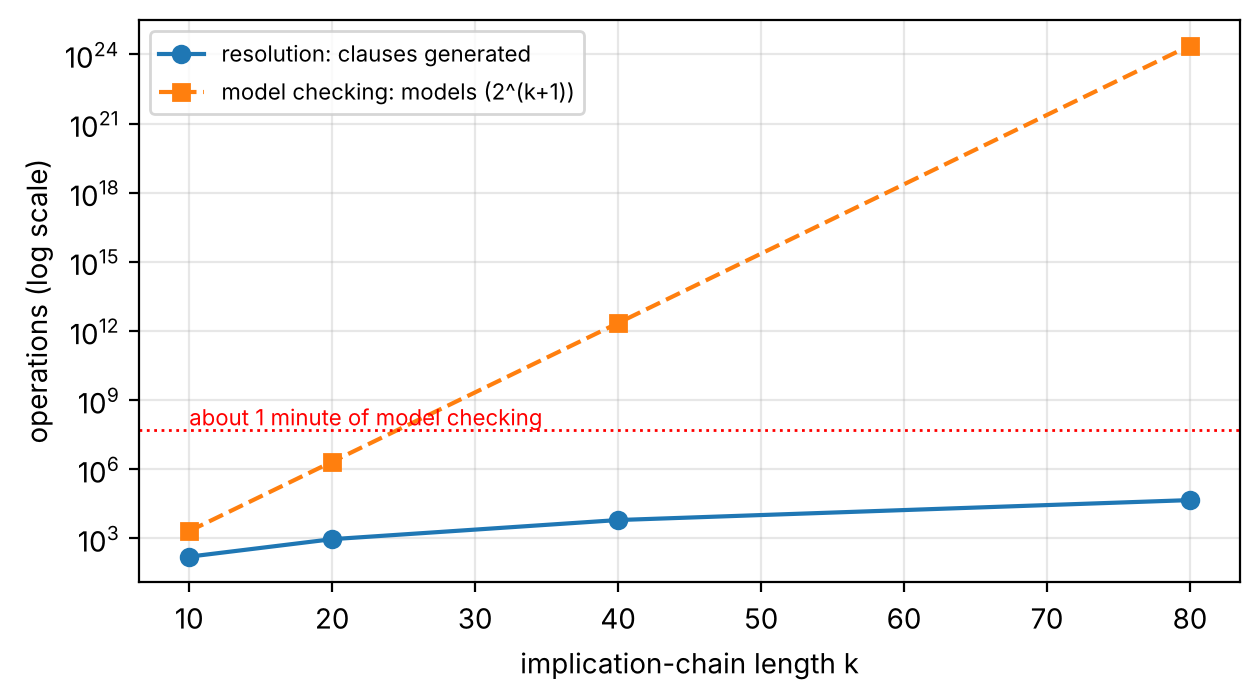

In [15]:
import matplotlib.pyplot as plt, csv
ch = [r for r in csv.DictReader(open('data/task2_chains.csv')) if r['query'] == 'entailed']
k = [int(r['chain']) for r in ch]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.semilogy(k, [int(r['generated']) for r in ch], 'o-', label='resolution: clauses generated')
ax.semilogy(k, [float(r['mc_models']) for r in ch], 's--', label='model checking: models (2^(k+1))')
ax.axhline(5e7, color='red', lw=1, ls=':'); ax.text(10, 8e7, 'about 1 minute of model checking', color='red', fontsize=8)
ax.set_xlabel('implication-chain length k'); ax.set_ylabel('operations (log scale)'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figures/task2_chains.png', dpi=200); plt.show()

## Shared first-order core (UNIFY, backward chaining)

In [16]:
%%writefile u3_fol.py
# First-order core shared by Tasks 3-7: terms, UNIFY, substitution composition,
# backward chaining (with negation as failure and built-ins) and forward chaining.
import itertools, sys
sys.setrecursionlimit(20000)

# Variables are strings starting with '?'; constants are other strings or numbers;
# compound terms and atoms are tuples (functor, arg1, ..., argn).
def is_var(t): return isinstance(t, str) and t.startswith('?')

class Stats:
    def __init__(self):
        self.unify = 0; self.goals = 0; self.max_depth = 0; self.inferences = 0

def walk(t, s):
    while is_var(t) and t in s:
        t = s[t]
    return t

def subst(s, t):
    """Apply substitution s to term t (fully)."""
    t = walk(t, s)
    if isinstance(t, tuple):
        return (t[0],) + tuple(subst(s, a) for a in t[1:])
    return t

def occurs(v, t, s):
    t = walk(t, s)
    if t == v: return True
    return isinstance(t, tuple) and any(occurs(v, a, s) for a in t[1:])

def unify(x, y, s=None, occurs_check=True, st=None):
    """Most general unifier extending s, or None. Bindings are kept in triangular
    form and resolved by walk(); subst() gives the composed result."""
    if st is not None: st.unify += 1
    s = {} if s is None else s
    stack = [(x, y)]
    s = dict(s)
    while stack:
        a, b = stack.pop()
        a, b = walk(a, s), walk(b, s)
        if a == b:
            continue
        if is_var(a):
            if occurs_check and occurs(a, b, s): return None
            s[a] = b
        elif is_var(b):
            if occurs_check and occurs(b, a, s): return None
            s[b] = a
        elif isinstance(a, tuple) and isinstance(b, tuple) and a[0] == b[0] and len(a) == len(b):
            stack.extend(zip(a[1:], b[1:]))
        else:
            return None
    return s

def compose(s1, s2):
    """Composition s1∘s2: apply s1 first, then s2 (as in SUBST(COMPOSE(θ1,θ2), p) =
    SUBST(θ2, SUBST(θ1, p)))."""
    out = {v: subst(s2, t) for v, t in s1.items()}
    for v, t in s2.items():
        if v not in out: out[v] = t
    return {v: t for v, t in out.items() if v != t}

def resolved(s):
    return {v: subst(s, t) for v, t in s.items()}

_counter = itertools.count()
def variables(t, out=None):
    out = set() if out is None else out
    if is_var(t): out.add(t)
    elif isinstance(t, tuple):
        for a in t[1:]: variables(a, out)
    return out

def standardize(rule):
    """Rename rule variables apart (fresh names for every use)."""
    head, body = rule
    vs = variables(head)
    for b in body: variables(b, vs)
    k = next(_counter)
    m = {v: f'{v}_{k}' for v in vs}
    return subst(m, head), [subst(m, b) for b in body]

BUILTINS = {'>=': lambda a, b: a >= b, '<': lambda a, b: a < b, '!=': lambda a, b: a != b}

class KB:
    """Definite clauses (head, [body]) plus facts indexed by predicate and by
    (predicate, argument position, value) so that any bound argument can be used."""
    def __init__(self, rules=(), facts=()):
        self.rules, self.by_head = [], {}
        self.facts, self.index, self.by_pred = set(), {}, {}
        for r in rules: self.add_rule(r)
        for f in facts: self.tell(f)
    def add_rule(self, r):
        self.rules.append(r); self.by_head.setdefault(r[0][0], []).append(r)
    def tell(self, f):
        if f in self.facts: return False
        self.facts.add(f)
        self.by_pred.setdefault(f[0], []).append(f)
        for i, a in enumerate(f[1:], 1):
            if not isinstance(a, tuple):
                self.index.setdefault((f[0], i, a), []).append(f)
        return True
    def candidates(self, goal):
        best = self.by_pred.get(goal[0], [])
        for i, a in enumerate(goal[1:], 1):
            if not is_var(a) and not isinstance(a, tuple):
                lst = self.index.get((goal[0], i, a), [])
                if len(lst) < len(best): best = lst
        return best

def bc_ask(kb, goal, st=None, depth_limit=10_000):
    """Backward chaining (depth-first, left-to-right) yielding substitutions."""
    st = st or Stats()
    def solve(goals, s, depth):
        if not goals:
            yield s; return
        g, rest = goals[0], goals[1:]
        if g[0] == 'not':                      # negation as failure (closed world)
            for _ in solve([g[1]], s, depth + 1):
                return
            yield from solve(rest, s, depth); return
        if g[0] in BUILTINS:
            a, b = subst(s, g[1]), subst(s, g[2])
            if BUILTINS[g[0]](a, b):
                yield from solve(rest, s, depth)
            return
        st.goals += 1; st.max_depth = max(st.max_depth, depth)
        if depth > depth_limit:
            raise RecursionError('depth limit')
        g2 = subst(s, g)
        for f in kb.candidates(g2):
            s2 = unify(g2, f, s, False, st)
            if s2 is not None:
                yield from solve(rest, s2, depth)
        for r in kb.by_head.get(g[0], []):
            head, body = standardize(r)
            s2 = unify(g2, head, s, False, st)
            if s2 is not None:
                st.inferences += 1
                yield from solve(body + rest, s2, depth + 1)
    yield from solve([goal], {}, 0)

def show_t(t):
    if isinstance(t, tuple):
        return f"{t[0]}({', '.join(show_t(a) for a in t[1:])})"
    return str(t)

Writing u3_fol.py


In [17]:
from u3_fol import *

## Task 3 - Exam-eligibility advisor in FOL

In [18]:
%%writefile u3_t3_exam.py
# Task 3 - Exam-eligibility advisor: knowledge engineering in FOL vs propositional encoding
import random, time, sys
from u3_fol import *

V = lambda n: '?' + n
s_, c_, p_, q_, g_, k_, l_, h_, i_ = (V(x) for x in 'scpqgklhi')

# ---- final (debugged) first-order axioms ----
AXIOMS = [
 (('Eligible', s_, c_), [('Registered', s_, c_), ('AttendanceOK', s_, c_), ('PrereqsCleared', s_, c_),
                         ('FeesCleared', s_), ('GoodStanding', s_), ('ExamReady', c_)]),            # A1
 (('AttendanceOK', s_, c_), [('Attendance', s_, c_, p_), ('>=', p_, 75)]),                           # A2
 (('AttendanceOK', s_, c_), [('Attendance', s_, c_, p_), ('>=', p_, 65), ('ApprovedLeave', s_, c_)]),# A3 condonation
 (('PrereqsCleared', s_, c_), [('Registered', s_, c_), ('not', ('MissingPrereq', s_, c_))]),         # A4
 (('MissingPrereq', s_, c_), [('Registered', s_, c_), ('Prereq', q_, c_), ('not', ('Passed', s_, q_))]),  # A5
 (('Passed', s_, q_), [('Grade', s_, q_, g_), ('PassGrade', g_)]),                                   # A6
 (('FeesCleared', s_), [('FeePaid', s_)]),                                                           # A7
 (('FeesCleared', s_), [('Scholarship', s_)]),                                                       # A8
 (('GoodStanding', s_), [('Student', s_), ('not', ('Debarred', s_))]),                               # A9
 (('Debarred', s_), [('DisciplinaryCase', s_, k_), ('Upheld', k_)]),                                 # A10
 (('ApprovedLeave', s_, c_), [('LeaveRequest', l_, s_, c_), ('ApprovedBy', l_, h_), ('HOD', h_)]),   # A11
 (('Registered', s_, c_), [('Enrolled', s_, c_), ('Offered', c_)]),                                  # A12
 (('ExamReady', c_), [('Offered', c_), ('Invigilator', i_, c_)]),                                    # A13 ∃i in the body
]

# ---- earlier versions kept for the defect log ----
def axioms_v1():
    ax = list(AXIOMS)
    ax[4] = (('MissingPrereq', s_, c_), [('Prereq', q_, c_), ('not', ('Passed', s_, q_))])   # D4: NAF with s unbound
    return ax

def axioms_v0():
    ax = [r for r in AXIOMS]
    ax[3] = (('PrereqsCleared', s_, c_), [('Prereq', q_, c_), ('Passed', s_, q_)])        # D1: one prerequisite enough
    ax.insert(4, (('PrereqsCleared', s_, c_), [('NoPrereq', c_)]))
    ax.pop(5)                                                                               # (MissingPrereq not yet defined)
    ax[8] = (('GoodStanding', s_), [('not', ('Debarred', s_)), ('Student', s_)])           # D2: NAF before s is bound
    ax = [r for r in ax if r[1] != [('Scholarship', s_)]]                                  # D3: scholarship forgotten
    return ax

def demo_facts():
    F = []
    for c in ('AI', 'DBMS', 'OS', 'CN'):
        F += [('Offered', c), ('Course', c)]
    F += [('Invigilator', 'DrRao', 'AI'), ('Invigilator', 'DrSen', 'DBMS'), ('Invigilator', 'DrIyer', 'OS')]   # CN has none
    F += [('Prereq', 'DS', 'AI'), ('Prereq', 'Maths', 'AI'), ('NoPrereq', 'DBMS'), ('NoPrereq', 'OS'), ('NoPrereq', 'CN')]
    F += [('PassGrade', g) for g in ('S', 'A', 'B', 'C', 'D', 'E')] + [('HOD', 'DrKumar')]
    people = {'Asha': dict(att={'AI': 82, 'DBMS': 90}, grades={'DS': 'A', 'Maths': 'B'}, fee='paid'),
              'Bala': dict(att={'AI': 70, 'DBMS': 68}, grades={'DS': 'B', 'Maths': 'C'}, fee='paid', leave=['AI']),
              'Chitra': dict(att={'AI': 88}, grades={'DS': 'A', 'Maths': 'F'}, fee='paid'),
              'Dev': dict(att={'AI': 95, 'OS': 91}, grades={'DS': 'S', 'Maths': 'A'}, fee='scholarship'),
              'Esha': dict(att={'DBMS': 85, 'OS': 60}, grades={}, fee='none'),
              'Farid': dict(att={'DBMS': 92, 'CN': 90}, grades={}, fee='paid', case='K7'),
              'Gopi': dict(att={'OS': 80}, grades={}, fee='paid', case='K9', upheld=False)}
    for name, d in people.items():
        F.append(('Student', name))
        for c, p in d['att'].items():
            F += [('Enrolled', name, c), ('Attendance', name, c, p)]
        for q, g in d['grades'].items():
            F.append(('Grade', name, q, g))
        if d['fee'] == 'paid': F.append(('FeePaid', name))
        if d['fee'] == 'scholarship': F.append(('Scholarship', name))
        for c in d.get('leave', []):
            F += [('LeaveRequest', f'L_{name}_{c}', name, c), ('ApprovedBy', f'L_{name}_{c}', 'DrKumar')]
        if 'case' in d:
            F.append(('DisciplinaryCase', name, d['case']))
            if d.get('upheld', True): F.append(('Upheld', d['case']))
    return F

QUERIES = [
 # (description, goal, expected) - expected True/False, or the set of bindings for the variable
 ('Asha may write AI', ('Eligible', 'Asha', 'AI'), True),
 ('Asha may write DBMS', ('Eligible', 'Asha', 'DBMS'), True),
 ('Bala may write AI (68-75% with approved leave)', ('Eligible', 'Bala', 'AI'), True),
 ('Dev may write AI (scholarship covers fees)', ('Eligible', 'Dev', 'AI'), True),
 ('Gopi may write OS (case not upheld)', ('Eligible', 'Gopi', 'OS'), True),
 ('Bala may write DBMS (68%, no leave)', ('Eligible', 'Bala', 'DBMS'), False),
 ('Chitra may write AI (failed Maths prerequisite)', ('Eligible', 'Chitra', 'AI'), False),
 ('Esha may write DBMS (fees unpaid)', ('Eligible', 'Esha', 'DBMS'), False),
 ('Farid may write DBMS (debarred)', ('Eligible', 'Farid', 'DBMS'), False),
 ('Asha may write CN (not enrolled, no invigilator)', ('Eligible', 'Asha', 'CN'), False),
 ('Who may write AI?', ('Eligible', s_, 'AI'), {'Asha', 'Bala', 'Dev'}),
 ('Which exams may Dev write?', ('Eligible', 'Dev', c_), {'AI', 'OS'}),
 ('Who is in good standing?', ('GoodStanding', s_), {'Asha', 'Bala', 'Chitra', 'Dev', 'Esha', 'Gopi'}),
 ('Which courses are exam-ready?', ('ExamReady', c_), {'AI', 'DBMS', 'OS'}),
 ('Who has a prerequisite missing for AI?', ('MissingPrereq', s_, 'AI'), {'Chitra'}),
]

def ask(kb, goal, expected):
    st = Stats()
    if isinstance(expected, set):
        var = next(iter(variables(goal)))
        got = {subst(s, var) for s in bc_ask(kb, goal, st)}
    else:
        got = next(bc_ask(kb, goal, st), None) is not None
    return got, st

def run_queries(axioms):
    kb = KB(axioms, demo_facts())
    rows = []
    for d, g, e in QUERIES:
        got, st = ask(kb, g, e)
        rows.append(dict(query=d, goal=show_t(g), expected=e, actual=got, ok=got == e, unify=st.unify, goals=st.goals))
    return rows

# ---- scaling: synthetic data, both encodings ----
def synthetic(students, courses, seed=1):
    rng = random.Random(seed)
    C = [f'C{j}' for j in range(courses)]
    F = [('PassGrade', g) for g in 'SABCDE'] + [('HOD', 'H1')]
    for j, c in enumerate(C):
        F += [('Offered', c), ('Invigilator', f'I{j}', c)]
        for q in rng.sample(C[:j], min(j, rng.randint(0, 2))):
            F.append(('Prereq', q, c))
    for i in range(students):
        s = f'S{i}'
        F.append(('Student', s))
        if rng.random() < 0.85: F.append(('FeePaid', s))
        elif rng.random() < 0.5: F.append(('Scholarship', s))
        if rng.random() < 0.05: F += [('DisciplinaryCase', s, f'K{i}'), ('Upheld', f'K{i}')]
        for c in C:
            F += [('Enrolled', s, c), ('Attendance', s, c, rng.randint(55, 100))]
            F.append(('Grade', s, c, rng.choice('SABCDEF')))
            if rng.random() < 0.1:
                F += [('LeaveRequest', f'L{i}{c}', s, c), ('ApprovedBy', f'L{i}{c}', 'H1')]
    return C, F

def propositionalise(students, courses, facts):
    """One set of ground rules per student and course (the propositional encoding).
    Arithmetic and negation are compiled into ground facts when the KB is built."""
    fs = set(facts)
    pre = {}
    for f in facts:
        if f[0] == 'Prereq': pre.setdefault(f[2], []).append(f[1])
    att = {(f[1], f[2]): f[3] for f in facts if f[0] == 'Attendance'}
    passed = {(f[1], f[2]) for f in facts if f[0] == 'Grade' and f[3] != 'F'}
    rules, base = [], set()
    for c in courses:
        rules.append((f'ExamReady_{c}', [f'Offered_{c}', f'HasInvigilator_{c}']))
        base |= {f'Offered_{c}', f'HasInvigilator_{c}'}
    for i in range(students):
        s = f'S{i}'
        rules += [(f'Fees_{s}', [f'FeePaid_{s}']), (f'Fees_{s}', [f'Scholar_{s}']), (f'Good_{s}', [f'NotDebarred_{s}'])]
        if ('FeePaid', s) in fs: base.add(f'FeePaid_{s}')
        if ('Scholarship', s) in fs: base.add(f'Scholar_{s}')
        if ('DisciplinaryCase', s, f'K{i}') not in fs: base.add(f'NotDebarred_{s}')
        for c in courses:
            rules.append((f'Eligible_{s}_{c}', [f'Registered_{s}_{c}', f'AttOK_{s}_{c}', f'Prereq_{s}_{c}',
                                                f'Fees_{s}', f'Good_{s}', f'ExamReady_{c}']))
            rules.append((f'Registered_{s}_{c}', [f'Enrolled_{s}_{c}', f'Offered_{c}']))
            rules.append((f'AttOK_{s}_{c}', [f'Att75_{s}_{c}']))
            rules.append((f'AttOK_{s}_{c}', [f'Att65_{s}_{c}', f'Leave_{s}_{c}']))
            rules.append((f'Prereq_{s}_{c}', [f'Passed_{s}_{q}' for q in pre.get(c, [])]))
            rules.append((f'Passed_{s}_{c}', [f'GradeOK_{s}_{c}']))
            base.add(f'Enrolled_{s}_{c}')
            if att[(s, c)] >= 75: base.add(f'Att75_{s}_{c}')
            if att[(s, c)] >= 65: base.add(f'Att65_{s}_{c}')
            if (s, c) in passed: base.add(f'GradeOK_{s}_{c}')
            if any(f[0] == 'LeaveRequest' and f[2] == s and f[3] == c for f in ()): pass
    for f in facts:
        if f[0] == 'LeaveRequest': base.add(f'Leave_{f[2]}_{f[3]}')
    return rules, base

def pl_fc_entails(rules, facts, q, st):
    """Forward chaining with an agenda (PL-FC-ENTAILS): linear in KB size per query."""
    count = [len(b) for _, b in rules]
    by_premise = {}
    for i, (_, b) in enumerate(rules):
        for p in b: by_premise.setdefault(p, []).append(i)
    inferred, agenda = set(), list(facts)
    for i, (h, b) in enumerate(rules):
        if not b: agenda.append(h)
    while agenda:
        p = agenda.pop()
        if p == q: return True
        if p in inferred: continue
        inferred.add(p)
        for i in by_premise.get(p, []):
            count[i] -= 1; st.inferences += 1
            if count[i] == 0: agenda.append(rules[i][0])
    return False

def scaling(sizes, n_queries=20, seed=3):
    rows = []
    for s, c in sizes:
        C, F = synthetic(s, c)
        rng = random.Random(seed)
        qs = [(f'S{rng.randrange(s)}', rng.choice(C)) for _ in range(n_queries)]
        t0 = time.perf_counter(); rules, base = propositionalise(s, C, F); build_p = time.perf_counter() - t0
        st_p = Stats(); t0 = time.perf_counter()
        ans_p = [pl_fc_entails(rules, base, f'Eligible_{a}_{b}', st_p) for a, b in qs]
        q_p = (time.perf_counter() - t0) / n_queries
        t0 = time.perf_counter(); kb = KB(AXIOMS, F); build_f = time.perf_counter() - t0
        st_f = Stats(); t0 = time.perf_counter()
        ans_f = [next(bc_ask(kb, ('Eligible', a, b), st_f), None) is not None for a, b in qs]
        q_f = (time.perf_counter() - t0) / n_queries
        rows.append(dict(students=s, courses=c, facts=len(F), prop_rules=len(rules), fol_axioms=len(AXIOMS),
                         prop_build_ms=build_p * 1000, prop_query_ms=q_p * 1000,
                         fol_build_ms=build_f * 1000, fol_query_ms=q_f * 1000,
                         prop_steps=st_p.inferences // n_queries, fol_unify=st_f.unify // n_queries,
                         agree=ans_p == ans_f))
    return rows

Writing u3_t3_exam.py


In [19]:
from u3_t3_exam import *

In [20]:
rows = run_queries(AXIOMS)
for i, r in enumerate(rows, 1):
    print(f"Q{i:<2} {r['query']:48} expected {str(r['expected']):28} actual {str(r['actual']):28} {'PASS' if r['ok'] else 'FAIL'}")
save_csv('task3_queries.csv', rows)
print('Defect log - queries that failed in earlier KB versions:')
for ver, ax in (('v0', axioms_v0()), ('v1', axioms_v1())):
    for r in run_queries(ax):
        if not r['ok']: print(f"  {ver}: {r['query']:48} expected {str(r['expected']):28} got {r['actual']}")

Q1  Asha may write AI                                expected True                         actual True                         PASS
Q2  Asha may write DBMS                              expected True                         actual True                         PASS
Q3  Bala may write AI (68-75% with approved leave)   expected True                         actual True                         PASS
Q4  Dev may write AI (scholarship covers fees)       expected True                         actual True                         PASS
Q5  Gopi may write OS (case not upheld)              expected True                         actual True                         PASS
Q6  Bala may write DBMS (68%, no leave)              expected False                        actual False                        PASS
Q7  Chitra may write AI (failed Maths prerequisite)  expected False                        actual False                        PASS
Q8  Esha may write DBMS (fees unpaid)                expected False         

s=   2 c= 2 facts     28 | prop rules     32 vs FOL axioms 13 | build    0.03 /   0.03 ms | query   0.017 / 0.096 ms | steps     45 / unify  15 | agree True
s=   5 c= 3 facts     76 | prop rules    108 vs FOL axioms 13 | build    0.07 /   0.06 ms | query   0.061 / 0.133 ms | steps    170 / unify  23 | agree True
s=  10 c= 3 facts    132 | prop rules    213 vs FOL axioms 13 | build    0.11 /   0.09 ms | query   0.109 / 0.133 ms | steps    324 / unify  24 | agree True
s=  10 c= 5 facts    201 | prop rules    335 vs FOL axioms 13 | build    0.20 /   0.13 ms | query   0.170 / 0.124 ms | steps    528 / unify  29 | agree True
s=  20 c= 5 facts    381 | prop rules    665 vs FOL axioms 13 | build    0.56 /   0.28 ms | query   0.347 / 0.142 ms | steps   1030 / unify  31 | agree True
s=  50 c= 5 facts    933 | prop rules   1655 vs FOL axioms 13 | build    1.13 /   0.57 ms | query   0.987 / 0.136 ms | steps   2575 / unify  30 | agree True
s= 100 c=10 facts   3449 | prop rules   6310 vs FOL axioms

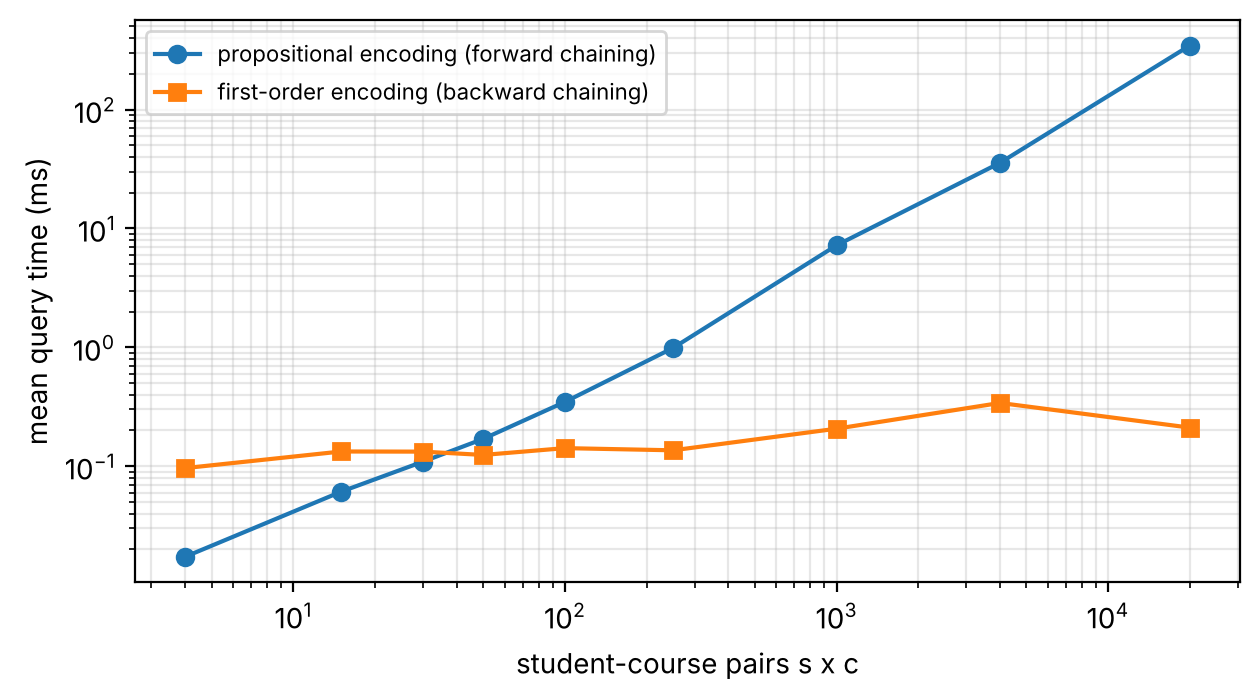

In [21]:
rows = scaling([(2, 2), (5, 3), (10, 3), (10, 5), (20, 5), (50, 5), (100, 10), (400, 10), (1000, 20)])
for r in rows:
    print(f"s={r['students']:4} c={r['courses']:2} facts {r['facts']:6} | prop rules {r['prop_rules']:6} vs FOL axioms {r['fol_axioms']} | "
          f"build {r['prop_build_ms']:7.2f} / {r['fol_build_ms']:6.2f} ms | query {r['prop_query_ms']:7.3f} / {r['fol_query_ms']:5.3f} ms | "
          f"steps {r['prop_steps']:6} / unify {r['fol_unify']:3} | agree {r['agree']}")
save_csv('task3_scaling.csv', rows)
import matplotlib.pyplot as plt
sc = [r['students'] * r['courses'] for r in rows]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.loglog(sc, [r['prop_query_ms'] for r in rows], 'o-', label='propositional encoding (forward chaining)')
ax.loglog(sc, [r['fol_query_ms'] for r in rows], 's-', label='first-order encoding (backward chaining)')
ax.set_xlabel('student-course pairs s x c'); ax.set_ylabel('mean query time (ms)'); ax.legend(fontsize=8); ax.grid(alpha=.3, which='both')
plt.tight_layout(); plt.savefig('figures/task3_crossover.png', dpi=200); plt.show()

## Task 4 - Unification and lifted inference

In [22]:
%%writefile u3_t4_unify.py
# Task 4 - UNIFY, lifted Modus Ponens and propositionalisation
import itertools, time
from u3_fol import *

x, y, z, w = '?x', '?y', '?z', '?w'

PAIRS = [
    ('Knows(John, x) vs Knows(y, Mother(y))', ('Knows', 'John', x), ('Knows', y, ('Mother', y))),
    ('P(x, f(y), z) vs P(g(z), f(A), w)', ('P', x, ('f', y), z), ('P', ('g', z), ('f', 'A'), w)),
    ('Loves(x, f(x), y) vs Loves(g(z), w, z)', ('Loves', x, ('f', x), y), ('Loves', ('g', z), w, z)),
    ('Q(x, x) vs Q(y, f(y))  [occurs check]', ('Q', x, x), ('Q', y, ('f', y))),
    ('Knows(John, x) vs Knows(x, Elizabeth)  [same x]', ('Knows', 'John', x), ('Knows', x, 'Elizabeth')),
]

def unify_report(a, b, occurs_check=True):
    s = unify(a, b, {}, occurs_check)
    if s is None: return None
    try:
        return {v: show_t(subst(s, t)) for v, t in sorted(s.items())}
    except RecursionError:
        return 'cyclic binding: ' + ', '.join(f'{v}/{show_t(t)}' for v, t in s.items())

def standardize_apart(t, suffix='1'):
    m = {v: v + suffix for v in variables(t)}
    return subst(m, t)

# ---------- lifted vs propositional on the same KB ----------
RULES = [
    (('Qualified', x), [('Employee', x), ('Certified', x)]),
    (('CanOperate', x, y), [('Qualified', x), ('Assigned', x, y), ('Machine', y)]),
    (('WorksAt', x, z), [('CanOperate', x, y), ('InPlant', y, z)]),
]

def facts(k):
    C = [f'c{i}' for i in range(k)]
    F = []
    for i, c in enumerate(C):
        if i % 2 == 0: F.append(('Employee', c))
        if i % 3 == 0: F.append(('Certified', c))
        if i % 4 == 1: F.append(('Machine', c))
        F.append(('Assigned', c, C[(i + 1) % k]))
        F.append(('InPlant', c, C[(i + 2) % k]))
    return C, F

def propositionalise(rules, constants):
    """Instantiate every universal rule with every combination of ground terms."""
    ground = []
    for head, body in rules:
        vs = sorted(variables(head) | set().union(*(variables(b) for b in body)))
        for combo in itertools.product(constants, repeat=len(vs)):
            m = dict(zip(vs, combo))
            ground.append((show_t(subst(m, head)), [show_t(subst(m, b)) for b in body]))
    return ground

def pl_fc(rules, facts, q):
    count = [len(b) for _, b in rules]
    by = {}
    for i, (_, b) in enumerate(rules):
        for p in b: by.setdefault(p, []).append(i)
    inferred, agenda, steps = set(), list(facts), 0
    while agenda:
        p = agenda.pop()
        if p == q: return True, steps
        if p in inferred: continue
        inferred.add(p)
        for i in by.get(p, []):
            count[i] -= 1; steps += 1
            if count[i] == 0: agenda.append(rules[i][0])
    return False, steps

def lifted_vs_prop(k, query=None):
    C, F = facts(k)
    query = query or ('WorksAt', 'c0', f'c{3 % k}')
    t0 = time.perf_counter()
    g = propositionalise(RULES, C)
    ok_p, steps_p = pl_fc(g, [show_t(f) for f in F], show_t(query))
    tp = time.perf_counter() - t0
    st = Stats(); t0 = time.perf_counter()
    ok_l = next(bc_ask(KB(RULES, F), query, st), None) is not None
    tl = time.perf_counter() - t0
    return dict(k=k, ground_clauses=len(g), prop_steps=steps_p, prop_ms=tp * 1000,
                lifted_unify=st.unify, lifted_rule_uses=st.inferences, lifted_ms=tl * 1000, same=ok_p == ok_l == True)

def arity_growth(k=5, max_arity=6):
    out = []
    for a in range(1, max_arity + 1):
        vs = [f'?v{i}' for i in range(a)]
        rule = (('Q',) + tuple(vs), [('P',) + tuple(vs)])
        out.append(dict(arity=a, k=k, ground_clauses=len(propositionalise([rule], [f'c{i}' for i in range(k)]))))
    return out

def ground_terms(k, depth, functions):
    """All ground terms up to nesting depth d built from k constants and the given
    function symbols {name: arity}."""
    terms = {f'c{i}' for i in range(k)}
    sizes = [len(terms)]
    for _ in range(depth):
        new = set(terms)
        for f, ar in functions.items():
            for args in itertools.product(sorted(terms, key=str), repeat=ar):
                new.add((f,) + args)
        terms = new
        sizes.append(len(terms))
    return sizes

def closure(rules, facts):
    """Forward chaining to a fixed point on ground rules (all consequences)."""
    count = [len(b) for _, b in rules]
    by = {}
    for i, (_, b) in enumerate(rules):
        for p in b: by.setdefault(p, []).append(i)
    inferred, agenda = set(), list(facts)
    while agenda:
        p = agenda.pop()
        if p in inferred: continue
        inferred.add(p)
        for i in by.get(p, []):
            count[i] -= 1
            if count[i] == 0: agenda.append(rules[i][0])
    return inferred

def many_queries(k):
    """Answer every WorksAt(a, b) query (k*k of them) with each approach."""
    C, F = facts(k)
    t0 = time.perf_counter()
    known = closure(propositionalise(RULES, C), [show_t(f) for f in F])
    ans_p = sum(f'WorksAt({a}, {b})' in known for a in C for b in C)
    tp = time.perf_counter() - t0
    kb = KB(RULES, F); st = Stats(); t0 = time.perf_counter()
    ans_l = sum(next(bc_ask(kb, ('WorksAt', a, b), st), None) is not None for a in C for b in C)
    tl = time.perf_counter() - t0
    return dict(k=k, queries=k * k, prop_ms=tp * 1000, lifted_ms=tl * 1000, lifted_unify=st.unify, same=ans_p == ans_l, true=ans_p)

Writing u3_t4_unify.py


In [23]:
from u3_t4_unify import *

In [24]:
for desc, a, b in PAIRS:
    print(f"{desc:48} MGU: {unify_report(a, b)}   | without occurs check: {unify_report(a, b, False)}")
b2 = standardize_apart(('Knows', '?x', 'Elizabeth'))
print('after standardising apart:', show_t(b2), '->', unify_report(('Knows', 'John', '?x'), b2))
s1, s2 = {'?x': ('f', '?y')}, {'?y': 'A'}
t = ('P', '?x', '?y')
print('compose({x/f(y)}, {y/A}) =', {v: show_t(u) for v, u in compose(s1, s2).items()},
      '| SUBST(compose) =', show_t(subst(compose(s1, s2), t)), '= SUBST(s2, SUBST(s1, t)) =', show_t(subst(s2, subst(s1, t))))

Knows(John, x) vs Knows(y, Mother(y))            MGU: {'?x': 'Mother(John)', '?y': 'John'}   | without occurs check: {'?x': 'Mother(John)', '?y': 'John'}
P(x, f(y), z) vs P(g(z), f(A), w)                MGU: {'?x': 'g(?w)', '?y': 'A', '?z': '?w'}   | without occurs check: {'?x': 'g(?w)', '?y': 'A', '?z': '?w'}
Loves(x, f(x), y) vs Loves(g(z), w, z)           MGU: {'?w': 'f(g(?z))', '?x': 'g(?z)', '?y': '?z'}   | without occurs check: {'?w': 'f(g(?z))', '?x': 'g(?z)', '?y': '?z'}
Q(x, x) vs Q(y, f(y))  [occurs check]            MGU: None   | without occurs check: cyclic binding: ?x/f(?y), ?y/f(?y)
Knows(John, x) vs Knows(x, Elizabeth)  [same x]  MGU: None   | without occurs check: None
after standardising apart: Knows(?x1, Elizabeth) -> {'?x': 'Elizabeth', '?x1': 'John'}
compose({x/f(y)}, {y/A}) = {'?x': 'f(A)', '?y': 'A'} | SUBST(compose) = P(f(A), A) = SUBST(s2, SUBST(s1, t)) = P(f(A), A)


k= 3: ground clauses     39 | propositional    24 steps     0.26 ms | lifted 8 unifications, 3 rule uses 0.107 ms | same answer True
k= 5: ground clauses    155 | propositional    50 steps     1.05 ms | lifted 8 unifications, 3 rule uses 0.086 ms | same answer True
k=10: ground clauses   1110 | propositional   179 steps     8.17 ms | lifted 8 unifications, 3 rule uses 0.100 ms | same answer True
k=15: ground clauses   3615 | propositional   388 steps    78.23 ms | lifted 8 unifications, 3 rule uses 0.186 ms | same answer True
k=20: ground clauses   8420 | propositional   657 steps    52.52 ms | lifted 8 unifications, 3 rule uses 0.228 ms | same answer True
k=25: ground clauses  16275 | propositional   997 steps   105.47 ms | lifted 8 unifications, 3 rule uses 0.231 ms | same answer True
k=30: ground clauses  27930 | propositional  1435 steps   181.71 ms | lifted 8 unifications, 3 rule uses 0.243 ms | same answer True
arity growth (k=5): [(1, 5), (2, 25), (3, 125), (4, 625), (5, 3125), 

ground terms with unary f, depth 0..5: [3, 6, 9, 12, 15, 18]
ground terms with binary g, depth 0..3: [3, 12, 147, 21612]


all   9 WorksAt queries, k= 3: propositional closure    0.48 ms | lifted   0.56 ms (62.7 us/query) | break-even after      8 queries
all  25 WorksAt queries, k= 5: propositional closure    1.69 ms | lifted   1.43 ms (57.1 us/query) | break-even after     30 queries
all 100 WorksAt queries, k=10: propositional closure   12.81 ms | lifted   5.66 ms (56.6 us/query) | break-even after    226 queries
all 400 WorksAt queries, k=20: propositional closure   83.72 ms | lifted  13.15 ms (32.9 us/query) | break-even after   2547 queries
all 900 WorksAt queries, k=30: propositional closure  152.72 ms | lifted  29.06 ms (32.3 us/query) | break-even after   4730 queries


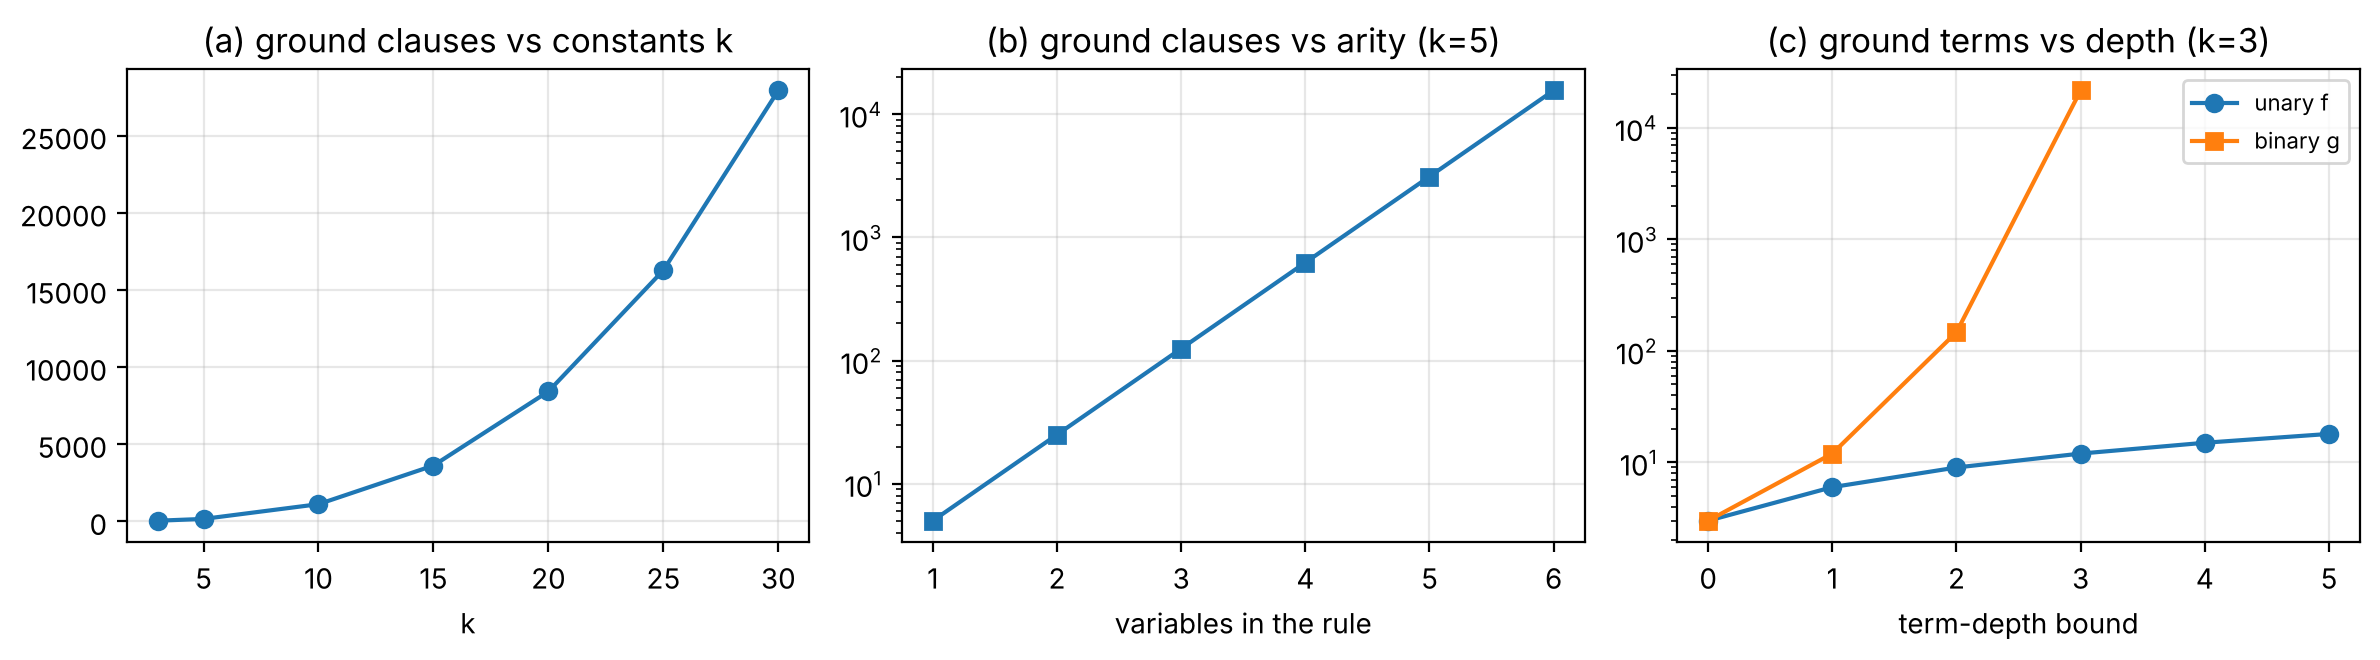

In [25]:
rows = [lifted_vs_prop(k) for k in (3, 5, 10, 15, 20, 25, 30)]
for r in rows:
    print(f"k={r['k']:2}: ground clauses {r['ground_clauses']:6} | propositional {r['prop_steps']:5} steps {r['prop_ms']:8.2f} ms | "
          f"lifted {r['lifted_unify']} unifications, {r['lifted_rule_uses']} rule uses {r['lifted_ms']:.3f} ms | same answer {r['same']}")
save_csv('task4_lifted_vs_prop.csv', rows)
ar = arity_growth(); print('arity growth (k=5):', [(r['arity'], r['ground_clauses']) for r in ar])
f1, g2 = ground_terms(3, 5, {'f': 1}), ground_terms(3, 3, {'g': 2})
print('ground terms with unary f, depth 0..5:', f1); print('ground terms with binary g, depth 0..3:', g2)
mq = [many_queries(k) for k in (3, 5, 10, 20, 30)]
for r in mq:
    per = r['lifted_ms'] / r['queries']
    print(f"all {r['queries']:3} WorksAt queries, k={r['k']:2}: propositional closure {r['prop_ms']:7.2f} ms | lifted {r['lifted_ms']:6.2f} ms "
          f"({per * 1000:.1f} us/query) | break-even after {r['prop_ms'] / per:6.0f} queries")
save_csv('task4_many_queries.csv', mq)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot([r['k'] for r in rows], [r['ground_clauses'] for r in rows], 'o-'); ax[0].set_title('(a) ground clauses vs constants k')
ax[0].set_xlabel('k'); ax[1].semilogy([r['arity'] for r in ar], [r['ground_clauses'] for r in ar], 's-'); ax[1].set_title('(b) ground clauses vs arity (k=5)')
ax[1].set_xlabel('variables in the rule'); ax[2].semilogy(range(len(f1)), f1, 'o-', label='unary f'); ax[2].semilogy(range(len(g2)), g2, 's-', label='binary g')
ax[2].set_title('(c) ground terms vs depth (k=3)'); ax[2].set_xlabel('term-depth bound'); ax[2].legend(fontsize=8)
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figures/task4_growth.png', dpi=200); plt.show()

## Task 5 - First-order resolution

In [26]:
%%writefile u3_t5_folres.py
# Task 5 - First-order resolution with Skolemisation, using the Task 4 unifier
import itertools
from collections import deque
from u3_fol import *

e, d, x = '?e', '?d', '?x'

# CNF after Skolemisation (E1 is the Skolem constant for "some employee" in statement 3)
CLAUSES = {
    'C1': [('-', ('Employee', e)), ('-', ('Handled', e, d)), ('-', ('Restricted', d)), ('+', ('Authorised', e))],
    'C2': [('-', ('Document', d)), ('-', ('PatientData', d)), ('+', ('Restricted', d))],
    'C3a': [('+', ('Employee', 'E1'))],
    'C3b': [('-', ('Document', d)), ('-', ('Audited', d)), ('+', ('Handled', 'E1', d))],
    'C4a': [('+', ('Document', 'R1'))],
    'C4b': [('+', ('PatientData', 'R1'))],
    'C4c': [('+', ('Audited', 'R1'))],
}
GOAL = [('-', ('Authorised', x))]                      # negation of  ∃x Authorised(x)
MANAGER = [('-', ('Employee', e)), ('+', ('Employee', ('mgr', e)))]   # every employee has a manager who is an employee

def lit_vars(c):
    vs = set()
    for _, a in c: variables(a, vs)
    return vs

_k = itertools.count()
def rename(c):
    m = {v: f'{v}_{next(_k)}' for v in lit_vars(c)}
    return [(s, subst(m, a)) for s, a in c]

def canon(c):
    """Variant-insensitive key: rename variables in order of appearance."""
    m, out = {}, []
    def r(t):
        if is_var(t):
            m.setdefault(t, f'?v{len(m)}'); return m[t]
        if isinstance(t, tuple): return (t[0],) + tuple(r(a) for a in t[1:])
        return t
    for s, a in sorted(c, key=lambda l: (l[0], show_t(l[1]))):
        out.append((s, r(a)))
    return tuple(sorted(set(out), key=lambda l: (l[0], show_t(l[1]))))

def resolvents(c1, c2, st):
    c1, c2 = rename(c1), rename(c2)
    out = []
    for i, (s1, a1) in enumerate(c1):
        for j, (s2, a2) in enumerate(c2):
            if s1 != s2 and a1[0] == a2[0]:
                th = unify(a1, a2, {}, True, st)
                if th is not None:
                    st.inferences += 1
                    r = [(s, subst(th, a)) for k, (s, a) in enumerate(c1) if k != i] + \
                        [(s, subst(th, a)) for k, (s, a) in enumerate(c2) if k != j]
                    r = list(dict.fromkeys(r))                      # factoring of identical literals
                    if not any((('+' if s == '-' else '-'), a) in r for s, a in r):   # drop tautologies
                        out.append(r)
    return out

def fol_resolution(clauses, goal, strategy='sos', cap=2000):
    """Given-clause resolution. 'sos': every resolution uses at least one clause
    descended from the negated goal. 'none': all pairs of clauses are resolved."""
    st = Stats()
    base = [list(c) for c in clauses]
    usable = list(base) if strategy == 'sos' else []
    todo = deque([goal] if strategy == 'sos' else base + [goal])
    seen = {canon(c) for c in base + [goal]}
    parent = {canon(c): None for c in base + [goal]}
    generated = 0
    while todo:
        g = todo.popleft()
        for p in list(usable):
            for r in resolvents(g, p, st):
                generated += 1
                key = canon(r)
                if key not in parent: parent[key] = (canon(g), canon(p))
                if not r:
                    return True, dict(generated=generated, steps=st.inferences, unify=st.unify,
                                      proof=proof_length(parent, key)), parent
                if key not in seen and generated < cap:
                    seen.add(key); todo.append(r)
        usable.append(g)
        if generated >= cap:
            break
    return (None if generated >= cap else False), dict(generated=generated, steps=st.inferences,
                                                       unify=st.unify, proof=0), parent

def proof_length(parent, key):
    seen, stack = set(), [key]
    while stack:
        k = stack.pop()
        if k in seen: continue
        seen.add(k)
        if parent.get(k): stack.extend(parent[k])
    return len(seen)

def show_clause(c):
    if not c: return '□ (empty clause)'
    return ' ∨ '.join(('¬' if s == '-' else '') + show_t(a) for s, a in c)

def proof_lines(parent, key=(), depth=0, out=None):
    out = [] if out is None else out
    out.append('    ' * depth + show_clause(list(key)))
    if parent.get(key):
        for p in parent[key]:
            proof_lines(parent, p, depth + 1, out)
    return out

# ----- propositional version of the same small domain (constants E1, R1) for comparison -----
def propositional_version():
    from u3_logic import Imp, And, Not
    kb = []
    for E in ('E1', 'R1'):
        for D in ('E1', 'R1'):
            kb.append(Imp(And(f'Employee_{E}', f'Handled_{E}_{D}', f'Restricted_{D}'), f'Authorised_{E}'))
            kb.append(Imp(And(f'Document_{D}', f'Audited_{D}'), f'Handled_E1_{D}'))
        kb.append(Imp(And(f'Document_{E}', f'PatientData_{E}'), f'Restricted_{E}'))
    kb += ['Employee_E1', 'Document_R1', 'PatientData_R1', 'Audited_R1']
    from u3_logic import Or
    return kb, Or('Authorised_E1', 'Authorised_R1')

NOT_ENTAILED = {
    'Authorised(mgr(E1))': [('-', ('Authorised', ('mgr', 'E1')))],
    '∃x Employee(x) ∧ Audited(x)': [('-', ('Employee', x)), ('-', ('Audited', x))],
}

Writing u3_t5_folres.py


In [27]:
from u3_t5_folres import *

In [28]:
for name, cl in CLAUSES.items(): print(f"{name:4} {show_clause(cl)}")
print('¬goal', show_clause(GOAL))
rows = []
for strat in ('sos', 'none'):
    res, st, par = fol_resolution(list(CLAUSES.values()), GOAL, strat)
    rows.append(dict(strategy=strat, result=res, **st))
    print(f"strategy {strat:4}: proved {res} | clauses generated {st['generated']:4} | resolution steps {st['steps']:4} | "
          f"unifications {st['unify']:4} | proof length {st['proof']}")
res, st, par = fol_resolution(list(CLAUSES.values()), GOAL, 'sos')
print('\n'.join(proof_lines(par)))
for name, g in NOT_ENTAILED.items():
    for strat in ('sos', 'none'):
        for cap in (50, 100, 200):
            res, st, _ = fol_resolution(list(CLAUSES.values()) + [MANAGER], g, strat, cap)
            rows.append(dict(strategy=f'{strat} cap {cap} [{name}]', result=res, **st))
            print(f"not entailed {name:28} {strat:4} cap {cap:3}: {'stopped at cap' if res is None else 'saturated: not entailed'} "
                  f"generated {st['generated']:4} unifications {st['unify']}")
from u3_t2_resolution import pl_resolution
kb, q = propositional_version(); res, st, _ = pl_resolution(kb, q)
print(f"propositional version (E1, R1): {len(kb)} sentences, input clauses {st['input_clauses']}, generated {st['generated']}, proved {res}")
save_csv('task5_resolution.csv', rows)

C1   ¬Employee(?e) ∨ ¬Handled(?e, ?d) ∨ ¬Restricted(?d) ∨ Authorised(?e)
C2   ¬Document(?d) ∨ ¬PatientData(?d) ∨ Restricted(?d)
C3a  Employee(E1)
C3b  ¬Document(?d) ∨ ¬Audited(?d) ∨ Handled(E1, ?d)
C4a  Document(R1)
C4b  PatientData(R1)
C4c  Audited(R1)
¬goal ¬Authorised(?x)
strategy sos : proved True | clauses generated   82 | resolution steps   82 | unifications   82 | proof length 15
strategy none: proved True | clauses generated  275 | resolution steps  275 | unifications  275 | proof length 16
□ (empty clause)
    ¬Audited(R1)
        ¬Audited(R1) ∨ ¬PatientData(R1)
            ¬Audited(?v0) ∨ ¬Document(?v0) ∨ ¬PatientData(?v0)
                ¬Document(?v0) ∨ ¬Handled(E1, ?v0) ∨ ¬PatientData(?v0)
                    ¬Document(?v0) ∨ ¬Employee(?v1) ∨ ¬Handled(?v1, ?v0) ∨ ¬PatientData(?v0)
                        ¬Employee(?v0) ∨ ¬Handled(?v0, ?v1) ∨ ¬Restricted(?v1)
                            ¬Authorised(?v0)
                            Authorised(?v0) ∨ ¬Employee(?v0) ∨ ¬Handled

not entailed ∃x Employee(x) ∧ Audited(x)  sos  cap 100: stopped at cap generated  101 unifications 201


not entailed ∃x Employee(x) ∧ Audited(x)  sos  cap 200: stopped at cap generated  201 unifications 401
not entailed ∃x Employee(x) ∧ Audited(x)  none cap  50: stopped at cap generated   52 unifications 62
not entailed ∃x Employee(x) ∧ Audited(x)  none cap 100: stopped at cap generated  102 unifications 121
not entailed ∃x Employee(x) ∧ Audited(x)  none cap 200: stopped at cap generated  201 unifications 273
propositional version (E1, R1): 14 sentences, input clauses 14, generated 235, proved True


## Task 6 - Forward and backward chaining

In [29]:
%%writefile u3_t6_chaining.py
# Task 6 - Forward chaining vs backward chaining on an organisation hierarchy
import random, time
from u3_fol import *

x, y, z, m, r = '?x', '?y', '?z', '?m', '?r'

RULES = [
    (('Superior', x, y), [('ReportsTo', y, x)]),                                     # R1
    (('Superior', x, z), [('ReportsTo', y, x), ('Superior', y, z)]),                 # R2 (right-recursive)
    (('Manages', x, y), [('ReportsTo', y, x)]),                                      # R3
    (('Director', x), [('Role', x, 'director')]),                                    # R4
    (('Peer', x, y), [('ReportsTo', x, m), ('ReportsTo', y, m)]),                    # R5
    (('CanApprove', x, r), [('Request', r, y), ('Amount', r, 'small'), ('Manages', x, y)]),     # R6
    (('CanApprove', x, r), [('Request', r, y), ('Superior', x, y), ('Director', x)]),          # R7
    (('Escalate', r, x), [('Request', r, y), ('Amount', r, 'large'), ('Manages', x, y)]),      # R8
    (('UnderDirector', x, z), [('Superior', z, x), ('Director', z)]),                         # R9  (not used by the query)
    (('NeedsReview', r), [('Request', r, y), ('Amount', r, 'large')]),               # R10
]
CLIMB = (('Superior', x, z), [('ReportsTo', z, y), ('Superior', x, y)])               # R2'' climbs from the employee
LEFT_RECURSIVE = (('Superior', x, z), [('Superior', x, y), ('ReportsTo', z, y)])     # R2' left-recursive

def org_facts(n_facts, branching=5, seed=7):
    """Tree of employees, about n_facts facts in total (ReportsTo, Role, Request, Amount)."""
    rng = random.Random(seed)
    F, people = [], ['e0']
    F.append(('Role', 'e0', 'director'))
    i = 1
    while len(F) < n_facts:
        boss = people[(i - 1) // branching]
        p = f'e{i}'; people.append(p)
        F.append(('ReportsTo', p, boss))
        if i <= branching: F.append(('Role', p, 'director'))
        if rng.random() < 0.15:
            rq = f'r{i}'
            F += [('Request', rq, p), ('Amount', rq, rng.choice(['small', 'large']))]
        i += 1
    return F[:n_facts]

def forward_chain(rules, facts):
    """Naive forward chaining to a fixed point: every rule is re-matched against all
    known facts on every iteration (with a predicate index for the joins)."""
    kb = KB((), facts)
    st = dict(iterations=0, firings=0, redundant=0, inferred=0)
    while True:
        st['iterations'] += 1
        new = []
        for head, body in rules:
            for s in match_body(kb, body, {}):
                st['firings'] += 1
                f = subst(s, head)
                if f in kb.facts or f in new:
                    st['redundant'] += 1
                else:
                    new.append(f)
        if not new:
            return kb, st
        for f in new:
            kb.tell(f); st['inferred'] += 1

def match_body(kb, body, s):
    if not body:
        yield s; return
    g = subst(s, body[0])
    for f in kb.candidates(g):
        s2 = unify(g, f, s, False)
        if s2 is not None:
            yield from match_body(kb, body[1:], s2)

def relevant_facts(kb, query_atom, rules):
    """Derived facts that appear in at least one proof of the query (backward slice)."""
    need, out, stack = set(), set(), [query_atom]
    while stack:
        g = stack.pop()
        if g in need: continue
        need.add(g)
        for head, body in rules:
            s = unify(head, g, {}, False)
            if s is None: continue
            for s2 in match_body(kb, [subst(s, b) for b in body], s):
                for b in body:
                    a = subst(s2, b)
                    if a not in need: stack.append(a)
    return need

def fc_experiment(n):
    F = org_facts(n)
    reqs = [f for f in F if f[0] == 'Request']
    q = ('CanApprove', 'e0', reqs[-1][1])                    # can the CEO approve the deepest request?
    t0 = time.perf_counter(); kb, st = forward_chain(RULES, F); sec = time.perf_counter() - t0
    derived = kb.facts - set(F)
    rel = relevant_facts(kb, q, RULES) & derived
    return dict(facts=n, inferred=st['inferred'], firings=st['firings'], redundant=st['redundant'],
                iterations=st['iterations'], irrelevant_pct=100 * (1 - len(rel) / len(derived)),
                answer=q in kb.facts, seconds=sec)

class BCStats(Stats):
    def __init__(self):
        super().__init__(); self.seen = {}; self.repeated = 0

def bc_counted(kb, goal, depth_limit=None, memo=False):
    """Backward chaining with substitutions. Records goals expanded, unifications,
    maximum depth and repeated subgoals. Optional depth bound or memoisation."""
    st = BCStats()
    table = {}
    def key(g):                                      # variant key: variable names do not matter
        m = {}
        def r(t):
            if is_var(t): m.setdefault(t, f'_{len(m)}'); return m[t]
            return (t[0],) + tuple(r(a) for a in t[1:]) if isinstance(t, tuple) else t
        return show_t(r(g))
    def solve(goals, s, depth):
        if not goals:
            yield s; return
        g = subst(s, goals[0])
        st.goals += 1; st.max_depth = max(st.max_depth, depth)
        k = key(g)
        st.seen[k] = st.seen.get(k, 0) + 1
        if st.seen[k] > 1: st.repeated += 1
        if depth_limit is not None and depth > depth_limit:
            return
        if memo and k in table:                      # answer from the table (complete or in progress)
            for ans in table.get(k, []):
                s2 = unify(g, ans, s, False, st)
                if s2 is not None: yield from solve(goals[1:], s2, depth)
            return
        answers = []
        def raw():
            for f in kb.candidates(g):
                s2 = unify(g, f, {}, False, st)
                if s2 is not None: yield subst(s2, g)
            for rule in kb.by_head.get(g[0], []):
                head, body = standardize(rule)
                s2 = unify(g, head, {}, False, st)
                if s2 is not None:
                    st.inferences += 1
                    for s3 in solve(body, s2, depth + 1):
                        yield subst(s3, g)
        if memo:
            table[k] = []                            # mark in progress: recursive calls see current answers
            changed = True
            while changed:                           # iterate to a fixed point (simple tabling)
                changed = False
                for a in list(raw()):
                    if a not in table[k]:
                        table[k].append(a); changed = True
            for a in table[k]:
                s2 = unify(g, a, s, False, st)
                if s2 is not None: yield from solve(goals[1:], s2, depth)
            return
        for a in raw():
            s2 = unify(g, a, s, False, st)
            if s2 is not None: yield from solve(goals[1:], s2, depth)
    return solve, st

def bc_experiment(n, climb=False):
    F = org_facts(n)
    reqs = [f for f in F if f[0] == 'Request']
    q = ('CanApprove', 'e0', reqs[-1][1])
    rules = [CLIMB if r == RULES[1] else r for r in RULES] if climb else RULES
    kb = KB(rules, F)
    solve, st = bc_counted(kb, q)
    t0 = time.perf_counter(); ok = next(solve([q], {}, 0), None) is not None; sec = time.perf_counter() - t0
    return dict(facts=n, answer=ok, goals=st.goals, unify=st.unify, rule_uses=st.inferences,
                max_depth=st.max_depth, repeated=st.repeated, seconds=sec)

def left_recursion_demo(n=100, limit=200):
    """Naive BC on the left-recursive rule: show unbounded descent, then remedies."""
    F = org_facts(n)
    target = F[-1][1] if F[-1][0] == 'ReportsTo' else 'e20'
    rules = [r for r in RULES if r[0][0] != 'Superior'] + [(('Superior', x, y), [('ReportsTo', y, x)]), LEFT_RECURSIVE]
    kb = KB(rules, F)
    q = ('Superior', 'e0', 'e99999')                          # not true: forces full search
    out = []
    solve, st = bc_counted(kb, q, depth_limit=limit)
    t0 = time.perf_counter()
    try:
        res = next(solve([q], {}, 0), None)
    except RecursionError:
        res = 'RecursionError'
    out.append(dict(method=f'naive (stopped at depth {limit})', answer=res is not None, goals=st.goals,
                    unify=st.unify, max_depth=st.max_depth, repeated=st.repeated, seconds=time.perf_counter() - t0))
    for name, kw in (('depth bound 8', dict(depth_limit=8)), ('memoisation (tabling)', dict(memo=True))):
        for qq, label in ((('Superior', 'e0', 'e30'), 'true query'), (q, 'false query')):
            solve, st = bc_counted(kb, qq, **kw)
            t0 = time.perf_counter(); res = next(solve([qq], {}, 0), None)
            out.append(dict(method=f'{name}, {label}', answer=res is not None, goals=st.goals, unify=st.unify,
                            max_depth=st.max_depth, repeated=st.repeated, seconds=time.perf_counter() - t0))
    return out

Writing u3_t6_chaining.py


In [30]:
from u3_t6_chaining import *

In [31]:
rows = []
for n in (100, 1000, 10000):
    r = fc_experiment(n); rows.append(r)
    print(f"{n:5} facts: inferred {r['inferred']:6} | firings {r['firings']:6} | redundant {r['redundant']:6} | "
          f"iterations {r['iterations']} | irrelevant {r['irrelevant_pct']:6.2f}% | answer {r['answer']} | {r['seconds']:.3f} s")
save_csv('task6_forward.csv', rows)

  100 facts: inferred    708 | firings   3135 | redundant   2427 | iterations 5 | irrelevant  99.29% | answer True | 0.028 s


 1000 facts: inferred   9203 | firings  45542 | redundant  36339 | iterations 6 | irrelevant  99.93% | answer True | 0.425 s


10000 facts: inferred 105557 | firings 667292 | redundant 561735 | iterations 8 | irrelevant  99.99% | answer True | 26.224 s


In [32]:
rows = []
for climb in (False, True):
    for n in (100, 1000, 10000):
        r = bc_experiment(n, climb); r['rule_R2'] = 'climb from employee' if climb else 'descend from superior'; rows.append(r)
        print(f"{r['rule_R2']:22} {n:5} facts: answer {r['answer']} | goals {r['goals']:5} | unifications {r['unify']:5} | "
              f"max depth {r['max_depth']} | repeated subgoals {r['repeated']} | {r['seconds'] * 1000:.2f} ms")
save_csv('task6_backward.csv', rows)
print('Left-recursive rule  Superior(x,z) <= Superior(x,y) AND ReportsTo(z,y):')
lr = left_recursion_demo()
for r in lr:
    print(f"  {r['method']:36} answer {str(r['answer']):5} goals {r['goals']:5} unify {r['unify']:5} max depth {r['max_depth']:3} "
          f"repeated {r['repeated']:5} {r['seconds'] * 1000:.2f} ms")
save_csv('task6_left_recursion.csv', lr)

descend from superior    100 facts: answer True | goals   107 | unifications   158 | max depth 5 | repeated subgoals 1 | 1.78 ms
descend from superior   1000 facts: answer True | goals  2222 | unifications  3119 | max depth 6 | repeated subgoals 1 | 25.97 ms


descend from superior  10000 facts: answer True | goals 13817 | unifications 19355 | max depth 8 | repeated subgoals 1 | 157.81 ms
climb from employee      100 facts: answer True | goals    14 | unifications    28 | max depth 4 | repeated subgoals 1 | 0.18 ms
climb from employee     1000 facts: answer True | goals    17 | unifications    34 | max depth 5 | repeated subgoals 1 | 0.21 ms
climb from employee    10000 facts: answer True | goals    23 | unifications    45 | max depth 7 | repeated subgoals 1 | 0.36 ms


Left-recursive rule  Superior(x,z) <= Superior(x,y) AND ReportsTo(z,y):
  naive (stopped at depth 200)         answer False goals 13046 unify 38331 max depth 201 repeated 12914 176.20 ms
  depth bound 8, true query            answer True  goals     9 unify    26 max depth   2 repeated     0 0.20 ms
  depth bound 8, false query           answer False goals   374 unify  1083 max depth   9 repeated   242 6.08 ms
  memoisation (tabling), true query    answer True  goals   240 unify   547 max depth   2 repeated   108 3.11 ms
  memoisation (tabling), false query   answer False goals   174 unify   464 max depth   2 repeated    42 2.87 ms


## Task 7 - Medication-safety advisor

In [33]:
%%writefile u3_t7_medsafe.py
# Task 7 - Medication-safety advisor: definite-clause FOL KB, indexed backward chaining
# with proof-tree explanations. The clinical rules are illustrative test knowledge for
# the assignment, not a clinical reference.
import random, time, tracemalloc
from u3_fol import *

p, d, d2, a, c = '?p', '?d', '?d2', '?a', '?c'

# Drug catalogue: drug -> classes
CATALOGUE = {
    'amoxicillin': ['penicillin'], 'cefalexin': ['cephalosporin'], 'cotrimoxazole': ['sulfonamide', 'trimethoprim'],
    'aspirin': ['nsaid', 'salicylate', 'antiplatelet'], 'ibuprofen': ['nsaid'], 'naproxen': ['nsaid'],
    'warfarin': ['anticoagulant'], 'apixaban': ['anticoagulant'], 'sertraline': ['ssri'], 'fluoxetine': ['ssri'],
    'phenelzine': ['maoi'], 'tramadol': ['opioid', 'serotonergic_opioid'], 'morphine': ['opioid'],
    'diazepam': ['benzodiazepine'], 'sildenafil': ['pde5_inhibitor'], 'nitroglycerin': ['nitrate'],
    'lisinopril': ['ace_inhibitor'], 'spironolactone': ['k_sparing_diuretic'], 'methotrexate': ['methotrexate'],
    'simvastatin': ['statin'], 'clarithromycin': ['macrolide'], 'digoxin': ['digoxin'], 'amiodarone': ['amiodarone'],
    'lithium': ['lithium'], 'propranolol': ['nonselective_beta_blocker'], 'metformin': ['biguanide'],
    'doxycycline': ['tetracycline'], 'ciprofloxacin': ['fluoroquinolone'], 'chlorphenamine': ['first_gen_antihistamine'],
    'paracetamol': ['analgesic'], 'pseudoephedrine': ['decongestant'],
}

def R(label, head, body, text):
    return dict(label=label, rule=(head, body), text=text)

def U(reason): return ('Unsafe', p, d, reason)
def RX(): return [('Prescribed', p, d)]

def base_rules():
    rs = [
        R('H1', ('AgeGroup', p, 'child'), [('Age', p, a), ('<', a, 12)], 'a patient younger than 12 is a child'),
        R('H2', ('AgeGroup', p, 'elderly'), [('Age', p, a), ('>=', a, 65)], 'a patient aged 65 or over is elderly'),
        R('H3', ('Takes', p, d), [('CurrentMed', p, d)], 'a current medicine is being taken'),
    ]
    allergy = [('penicillin', 'penicillin'), ('penicillin', 'cephalosporin'), ('sulfonamide', 'sulfonamide'),
               ('nsaid', 'nsaid'), ('salicylate', 'salicylate')]
    for i, (alg, cls) in enumerate(allergy, 1):
        rs.append(R(f'A{i}', U(f'allergy:{alg}->{cls}'), RX() + [('InClass', d, cls), ('AllergicTo', p, alg)],
                    f'{cls} drug prescribed to a patient allergic to {alg}'))
    inter = [('nsaid', 'anticoagulant', 'bleeding risk'), ('antiplatelet', 'anticoagulant', 'bleeding risk'),
             ('anticoagulant', 'nsaid', 'bleeding risk'), ('ssri', 'maoi', 'serotonin syndrome'),
             ('maoi', 'ssri', 'serotonin syndrome'), ('serotonergic_opioid', 'ssri', 'serotonin syndrome'),
             ('pde5_inhibitor', 'nitrate', 'severe hypotension'), ('nitrate', 'pde5_inhibitor', 'severe hypotension'),
             ('k_sparing_diuretic', 'ace_inhibitor', 'hyperkalaemia'), ('trimethoprim', 'methotrexate', 'bone-marrow toxicity'),
             ('macrolide', 'statin', 'myopathy'), ('amiodarone', 'digoxin', 'digoxin toxicity'),
             ('nsaid', 'lithium', 'lithium toxicity'), ('opioid', 'benzodiazepine', 'respiratory depression'),
             ('benzodiazepine', 'opioid', 'respiratory depression')]
    for i, (c1, c2, why) in enumerate(inter, 1):
        rs.append(R(f'I{i}', U(f'interaction:{c1}+{c2}'),
                    RX() + [('InClass', d, c1), ('Takes', p, d2), ('InClass', d2, c2)],
                    f'{c1} with current {c2}: {why}'))
    cond = [('nsaid', 'chronic_kidney_disease'), ('nsaid', 'peptic_ulcer'), ('ace_inhibitor', 'pregnancy'),
            ('statin', 'pregnancy'), ('anticoagulant', 'active_bleeding'), ('nonselective_beta_blocker', 'asthma'),
            ('biguanide', 'severe_renal_impairment'), ('decongestant', 'uncontrolled_hypertension'),
            ('fluoroquinolone', 'myasthenia_gravis')]
    for i, (cls, k) in enumerate(cond, 1):
        rs.append(R(f'C{i}', U(f'condition:{cls}|{k}'), RX() + [('InClass', d, cls), ('HasCondition', p, k)],
                    f'{cls} is contraindicated in {k}'))
    age = [('salicylate', 'child'), ('tetracycline', 'child'), ('fluoroquinolone', 'child'),
           ('benzodiazepine', 'elderly'), ('first_gen_antihistamine', 'elderly')]
    for i, (cls, g) in enumerate(age, 1):
        rs.append(R(f'G{i}', U(f'age:{cls}|{g}'), RX() + [('InClass', d, cls), ('AgeGroup', p, g)],
                    f'{cls} should be avoided in a {g} patient'))
    dup = ['nsaid', 'ssri', 'anticoagulant']
    for i, cls in enumerate(dup, 1):
        rs.append(R(f'D{i}', U(f'duplicate:{cls}'),
                    RX() + [('InClass', d, cls), ('Takes', p, d2), ('!=', d, d2), ('InClass', d2, cls)],
                    f'two {cls} drugs at the same time'))
    return rs                                                         # 3 + 5 + 15 + 9 + 5 + 3 = 40

def synthetic_rules(n, seed=11):
    """Extra rules of the same shapes over synthetic drug classes, to grow the KB."""
    rng = random.Random(seed)
    rs = []
    for i in range(n):
        c1, c2 = f'cls{rng.randrange(400)}', f'cls{rng.randrange(400)}'
        kind = rng.choice(['I', 'C', 'A'])
        if kind == 'I':
            rs.append(R(f'S{i}', U(f'interaction:{c1}+{c2}'), RX() + [('InClass', d, c1), ('Takes', p, d2), ('InClass', d2, c2)], f'{c1} with {c2}'))
        elif kind == 'C':
            k = f'cond{rng.randrange(150)}'
            rs.append(R(f'S{i}', U(f'condition:{c1}|{k}'), RX() + [('InClass', d, c1), ('HasCondition', p, k)], f'{c1} in {k}'))
        else:
            rs.append(R(f'S{i}', U(f'allergy:{c2}->{c1}'), RX() + [('InClass', d, c1), ('AllergicTo', p, c2)], f'{c1} allergy {c2}'))
    return rs

def catalogue_facts(seed=5):
    rng = random.Random(seed)
    F = [('InClass', drug, cl) for drug, cls in CATALOGUE.items() for cl in cls]
    for j in range(800):                                         # synthetic drugs
        for cl in rng.sample(range(400), rng.randint(1, 2)):
            F.append(('InClass', f'drug{j}', f'cls{cl}'))
    return F

def patient_facts(n, seed=9):
    rng = random.Random(seed)
    real = list(CATALOGUE); conds = ['chronic_kidney_disease', 'peptic_ulcer', 'pregnancy', 'asthma', 'cond3', 'cond7']
    F = []
    for i in range(n):
        pid = f'P{i}'
        F.append(('Age', pid, rng.randint(1, 95)))
        for drug in rng.sample(real, rng.randint(0, 3)) + [f'drug{rng.randrange(800)}' for _ in range(rng.randint(0, 2))]:
            F.append(('CurrentMed', pid, drug))
        if rng.random() < 0.2: F.append(('AllergicTo', pid, rng.choice(['penicillin', 'sulfonamide', 'nsaid', f'cls{rng.randrange(400)}'])))
        for k in rng.sample(conds, rng.randint(0, 2)): F.append(('HasCondition', pid, k))
    return F

class Advisor:
    """Rules are indexed by the drug class that the prescribed drug must belong to
    (the first InClass(?d, class) literal), so a query only touches the rules that
    can possibly apply to the new drug."""
    def __init__(self, rules, facts, indexed=True):
        self.rules, self.indexed = rules, indexed
        self.kb = KB([r['rule'] for r in rules if r['rule'][0][0] != 'Unsafe'], facts)
        self.helpers = {r['rule'][0][0]: [] for r in rules}
        for r in rules:
            if r['rule'][0][0] != 'Unsafe': self.helpers[r['rule'][0][0]].append(r)
        self.by_class, self.unsafe = {}, [r for r in rules if r['rule'][0][0] == 'Unsafe']
        for r in self.unsafe:
            cls = next(b[2] for b in r['rule'][1] if b[0] == 'InClass' and b[1] == d)
            self.by_class.setdefault(cls, []).append(r)

    def prove(self, goals, s, st, depth=0):
        """Backward chaining that also returns the proof (facts and rules used)."""
        if not goals:
            yield s, []; return
        g = subst(s, goals[0]); rest = goals[1:]
        if g[0] in BUILTINS:
            if BUILTINS[g[0]](g[1], g[2]):
                for s2, pr in self.prove(rest, s, st, depth): yield s2, [f'{show_t(g)} (built-in)'] + pr
            return
        st.goals += 1; st.max_depth = max(st.max_depth, depth)
        for f in self.kb.candidates(g):
            s2 = unify(g, f, s, False, st)
            if s2 is not None:
                for s3, pr in self.prove(rest, s2, st, depth): yield s3, [f'{show_t(f)} (fact)'] + pr
        for r in self.helpers.get(g[0], []):
            head, body = standardize(r['rule'])
            s2 = unify(g, head, s, False, st)
            if s2 is not None:
                st.inferences += 1
                for s3, pr in self.prove(body, s2, st, depth + 1):
                    for s4, pr2 in self.prove(rest, s3, st, depth):
                        yield s4, [f"{show_t(subst(s3, head))} by {r['label']}: {r['text']}"] + pr + pr2

    def check(self, patient, drug):
        st = Stats()
        self.kb.tell(('Prescribed', patient, drug))
        if self.indexed:
            classes = [f[2] for f in self.kb.candidates(('InClass', drug, '?c'))]
            cand = [r for cl in classes for r in self.by_class.get(cl, [])]
        else:
            cand = self.unsafe
        found = []
        for r in cand:
            head, body = standardize(r['rule'])
            s0 = unify(('Unsafe', patient, drug, '?why'), head, {}, False, st)
            if s0 is None: continue
            st.inferences += 1
            for s, pr in self.prove(body, s0, st, 1):
                found.append((r, [f"Unsafe({patient}, {drug}) by {r['label']}: {r['text']}"] + pr))
                break
        self.kb.facts.discard(('Prescribed', patient, drug))
        for lst in (self.kb.by_pred.get('Prescribed', []), self.kb.index.get(('Prescribed', 1, patient), []),
                    self.kb.index.get(('Prescribed', 2, drug), [])):
            if ('Prescribed', patient, drug) in lst: lst.remove(('Prescribed', patient, drug))
        return found, st

# ---------- 30 designed test cases ----------
def test_patients():
    T = []
    def case(pid, age, meds, drug, expect, allergies=(), conds=(), note=''):
        T.append(dict(pid=pid, age=age, meds=meds, drug=drug, expect=expect, allergies=allergies, conds=conds, note=note))
    case('T01', 40, ['warfarin'], 'ibuprofen', 'interaction', note='warfarin + NSAID')
    case('T02', 70, ['warfarin'], 'aspirin', 'interaction', note='warfarin + aspirin')
    case('T03', 35, ['sertraline'], 'phenelzine', 'interaction', note='SSRI + MAOI')
    case('T04', 50, ['fluoxetine'], 'tramadol', 'interaction', note='SSRI + tramadol')
    case('T05', 62, ['nitroglycerin'], 'sildenafil', 'interaction', note='nitrate + PDE5 inhibitor')
    case('T06', 68, ['lisinopril'], 'spironolactone', 'interaction', note='ACE inhibitor + K-sparing diuretic')
    case('T07', 55, ['methotrexate'], 'cotrimoxazole', 'interaction', note='methotrexate + trimethoprim')
    case('T08', 60, ['simvastatin'], 'clarithromycin', 'interaction', note='statin + macrolide')
    case('T09', 75, ['digoxin'], 'amiodarone', 'interaction', note='digoxin + amiodarone')
    case('T10', 45, ['lithium'], 'naproxen', 'interaction', note='lithium + NSAID')
    case('T11', 58, ['morphine'], 'diazepam', 'interaction', note='opioid + benzodiazepine')
    case('T12', 30, [], 'amoxicillin', 'allergy', allergies=['penicillin'], note='penicillin allergy')
    case('T13', 30, [], 'cefalexin', 'allergy', allergies=['penicillin'], note='penicillin -> cephalosporin cross-reactivity')
    case('T14', 42, [], 'cotrimoxazole', 'allergy', allergies=['sulfonamide'], note='sulfa allergy')
    case('T15', 25, [], 'ibuprofen', 'allergy', allergies=['nsaid'], note='NSAID allergy')
    case('T16', 66, [], 'ibuprofen', 'condition', conds=['chronic_kidney_disease'], note='NSAID in CKD')
    case('T17', 29, [], 'lisinopril', 'condition', conds=['pregnancy'], note='ACE inhibitor in pregnancy')
    case('T18', 33, [], 'propranolol', 'condition', conds=['asthma'], note='non-selective beta-blocker in asthma')
    case('T19', 52, [], 'naproxen', 'condition', conds=['peptic_ulcer'], note='NSAID with peptic ulcer')
    case('T20', 7, [], 'aspirin', 'age', note='aspirin in a child')
    case('T21', 6, [], 'doxycycline', 'age', note='tetracycline in a child')
    case('T22', 80, [], 'diazepam', 'age', note='benzodiazepine in the elderly')
    case('T23', 78, [], 'chlorphenamine', 'age', note='first-generation antihistamine in the elderly')
    case('T24', 40, ['ibuprofen'], 'naproxen', 'duplicate', note='two NSAIDs')
    case('T25', 81, ['warfarin', 'sertraline'], 'ibuprofen', 'interaction', note='several hazards at once')
    case('T26', 30, [], 'paracetamol', 'safe', note='no hazard')
    case('T27', 45, ['lisinopril'], 'paracetamol', 'safe', note='unrelated current medicine')
    case('T28', 30, [], 'amoxicillin', 'safe', allergies=['sulfonamide'], note='allergy to an unrelated class')
    case('T29', 40, ['sertraline'], 'paracetamol', 'safe', note='SSRI, non-serotonergic analgesic')
    case('T30', 64, [], 'diazepam', 'safe', note='age 64: just below the elderly threshold')
    return T

def facts_for(t):
    F = [('Age', t['pid'], t['age'])] + [('CurrentMed', t['pid'], m) for m in t['meds']]
    F += [('AllergicTo', t['pid'], x) for x in t['allergies']] + [('HasCondition', t['pid'], k) for k in t['conds']]
    return F

def run_tests(adv):
    rows = []
    for t in test_patients():
        for f in facts_for(t): adv.kb.tell(f)
        found, st = adv.check(t['pid'], t['drug'])
        kinds = sorted({r['rule'][0][3].split(':')[0] for r, _ in found})
        verdict = 'safe' if not found else kinds
        ok = (t['expect'] == 'safe' and not found) or (t['expect'] != 'safe' and t['expect'] in kinds)
        rows.append(dict(case=t['pid'], note=t['note'], drug=t['drug'], expected=t['expect'],
                         verdict='SAFE' if not found else 'UNSAFE: ' + ', '.join(kinds), ok=ok,
                         goals=st.goals, unify=st.unify,
                         explanation=found[0][1] if found else [], rules_fired=len(found)))
    return rows

def build(n_rules, n_patients):
    rules = base_rules() + synthetic_rules(n_rules - 40)
    facts = catalogue_facts() + patient_facts(n_patients)
    return rules, facts

def scale_experiment(sizes=(40, 400, 2000), n_patients=50_000, n_queries=300, seed=2):
    rows = []
    rng = random.Random(seed)
    synth = [f'drug{j}' for j in range(800)]
    queries = [(f'P{rng.randrange(n_patients)}', rng.choice(list(CATALOGUE)) if i % 2 == 0 else rng.choice(synth))
               for i in range(n_queries)]                        # half real drugs, half synthetic
    for n in sizes:
        rules, facts = build(n, n_patients)
        tracemalloc.start()
        adv = Advisor(rules, facts, indexed=True)
        mem = tracemalloc.get_traced_memory()[0] / 2 ** 20
        tracemalloc.stop()
        base = Advisor(rules, facts, indexed=False)
        for f in [f for t in test_patients() for f in facts_for(t)]:
            adv.kb.tell(f); base.kb.tell(f)
        acc = sum(r['ok'] for r in run_tests(adv))
        res = {}
        for name, a in (('indexed', adv), ('baseline', base)):
            g = u = 0; expl = []; unsafe = 0
            t0 = time.perf_counter()
            for pid, drug in queries:
                found, st = a.check(pid, drug)
                g += st.goals; u += st.unify
                if found: unsafe += 1; expl.append(len(found[0][1]))
            res[name] = dict(ms=(time.perf_counter() - t0) * 1000 / n_queries, goals=g / n_queries,
                             unify=u / n_queries, unsafe=unsafe, expl=sum(expl) / max(1, len(expl)))
        rows.append(dict(rules=n, patients=n_patients, facts=len(facts), memory_mb=round(mem, 1), tests_passed=acc,
                         idx_ms=res['indexed']['ms'], idx_goals=res['indexed']['goals'], idx_unify=res['indexed']['unify'],
                         base_ms=res['baseline']['ms'], base_goals=res['baseline']['goals'], base_unify=res['baseline']['unify'],
                         same_unsafe=res['indexed']['unsafe'] == res['baseline']['unsafe'], unsafe=res['indexed']['unsafe'],
                         expl_len=res['indexed']['expl']))
    return rows

Writing u3_t7_medsafe.py


In [34]:
from u3_t7_medsafe import *

In [35]:
rules, facts = build(40, 1000)
adv = Advisor(rules, facts)
rows = run_tests(adv)
for r in rows:
    print(f"{r['case']} {r['note']:42} new: {r['drug']:13} expected {r['expected']:11} -> {r['verdict']:22} "
          f"{'PASS' if r['ok'] else 'FAIL'} goals {r['goals']:2}")
print('passed', sum(r['ok'] for r in rows), 'of', len(rows))
save_csv('task7_tests.csv', [{k: v for k, v in r.items() if k != 'explanation'} for r in rows])
for i in (0, 19):
    print(f"Explanation for {rows[i]['case']}:"); print('   ' + '\n   '.join(rows[i]['explanation']))

T01 warfarin + NSAID                           new: ibuprofen     expected interaction -> UNSAFE: interaction    PASS goals 24
T02 warfarin + aspirin                         new: aspirin       expected interaction -> UNSAFE: interaction    PASS goals 36
T03 SSRI + MAOI                                new: phenelzine    expected interaction -> UNSAFE: interaction    PASS goals  5
T04 SSRI + tramadol                            new: tramadol      expected interaction -> UNSAFE: interaction    PASS goals 10
T05 nitrate + PDE5 inhibitor                   new: sildenafil    expected interaction -> UNSAFE: interaction    PASS goals  5
T06 ACE inhibitor + K-sparing diuretic         new: spironolactone expected interaction -> UNSAFE: interaction    PASS goals  5
T07 methotrexate + trimethoprim                new: cotrimoxazole expected interaction -> UNSAFE: interaction    PASS goals  8
T08 statin + macrolide                         new: clarithromycin expected interaction -> UNSAFE: interaction

  40 rules, 50000 patients (236253 facts), KB memory 37.4 MB, tests 30/30 | indexed 0.039 ms, 4.3 goals, 6.0 unif | baseline 0.660 ms, 76.5 goals | same verdicts True (23 unsafe) | explanation 5.2 lines
 400 rules, 50000 patients (236253 facts), KB memory 37.4 MB, tests 30/30 | indexed 0.058 ms, 7.1 goals, 9.9 unif | baseline 6.503 ms, 798.0 goals | same verdicts True (23 unsafe) | explanation 5.2 lines
2000 rules, 50000 patients (236253 facts), KB memory 37.5 MB, tests 30/30 | indexed 0.131 ms, 18.5 goals, 25.6 unif | baseline 34.944 ms, 4003.8 goals | same verdicts True (24 unsafe) | explanation 5.2 lines


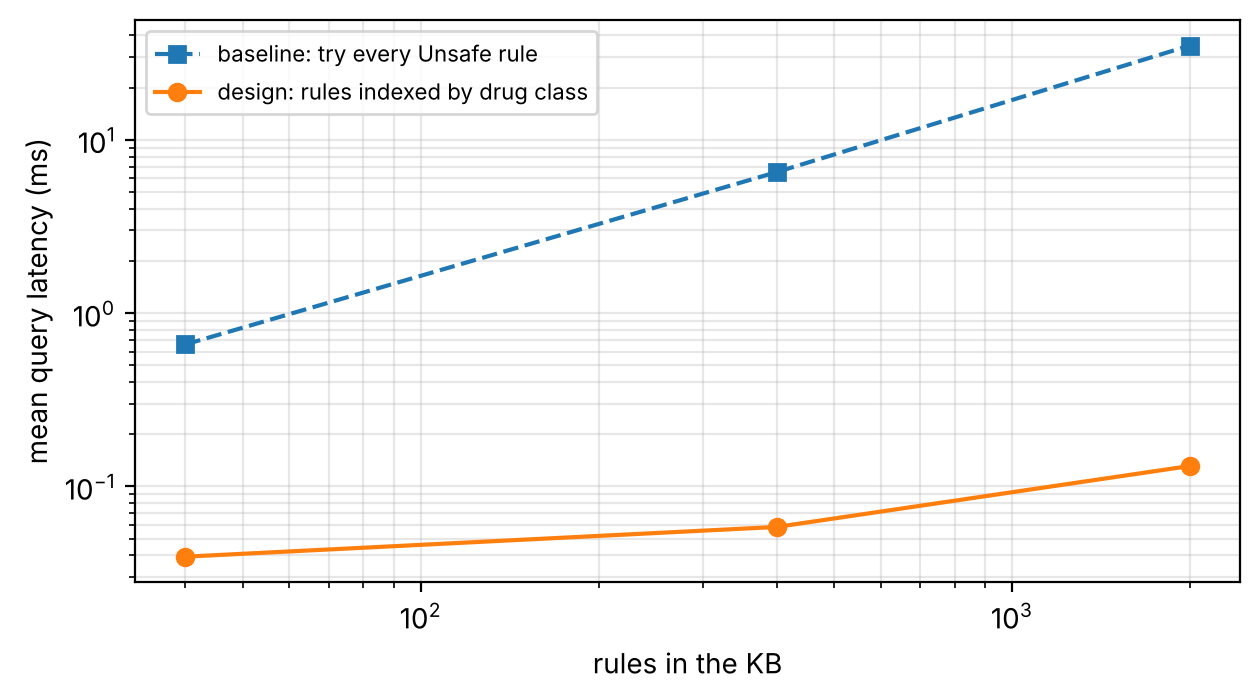

In [36]:
rows = scale_experiment((40, 400, 2000), n_patients=50_000, n_queries=300)
for r in rows:
    print(f"{r['rules']:4} rules, {r['patients']} patients ({r['facts']} facts), KB memory {r['memory_mb']} MB, tests {r['tests_passed']}/30 | "
          f"indexed {r['idx_ms']:.3f} ms, {r['idx_goals']:.1f} goals, {r['idx_unify']:.1f} unif | baseline {r['base_ms']:.3f} ms, "
          f"{r['base_goals']:.1f} goals | same verdicts {r['same_unsafe']} ({r['unsafe']} unsafe) | explanation {r['expl_len']:.1f} lines")
save_csv('task7_scale.csv', rows)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.4, 3.6))
n = [r['rules'] for r in rows]
ax.loglog(n, [r['base_ms'] for r in rows], 's--', label='baseline: try every Unsafe rule')
ax.loglog(n, [r['idx_ms'] for r in rows], 'o-', label='design: rules indexed by drug class')
ax.set_xlabel('rules in the KB'); ax.set_ylabel('mean query latency (ms)'); ax.legend(fontsize=8); ax.grid(alpha=.3, which='both')
plt.tight_layout(); plt.savefig('figures/task7_latency.png', dpi=200); plt.show()